In [4]:
# ============================================================
# SECTION 1 - CELL 1
# AUTOMATIC DATASET LOCATION AND VERIFICATION
# ============================================================

import os
from pathlib import Path

INPUT_ROOT = Path("/kaggle/input")

EXPECTED_FOLDERS = {
    "calculus",
    "data caries",
    "gingivitis",
    "mouth ulcer",
    "tooth discoloration",
    "hypodontia"
}

DATA_ROOT = None

# Find the folder containing our six disease classes
for current_path, folders, files in os.walk(INPUT_ROOT):

    folder_names = {
        name.lower() for name in folders
    }

    matches = folder_names.intersection(EXPECTED_FOLDERS)

    if len(matches) >= 4:
        DATA_ROOT = Path(current_path)
        break

if DATA_ROOT is None:
    print("Dataset folder not found.")
    print("\nAvailable folders:")

    for root, dirs, files in os.walk(INPUT_ROOT):
        print(root)

        if len(Path(root).relative_to(INPUT_ROOT).parts) >= 3:
            dirs[:] = []

    raise RuntimeError("Please share the folder output.")

print("=" * 60)
print("DATASET SUCCESSFULLY LOCATED")
print("=" * 60)

print("\nDataset path:", DATA_ROOT)
print("Dataset exists:", DATA_ROOT.exists())

print("\nCLASS FOLDERS:")

for folder in sorted(DATA_ROOT.iterdir()):
    if folder.is_dir():
        print(" -", folder.name)

# Count images
extensions = {
    ".jpg", ".jpeg", ".png",
    ".webp", ".bmp", ".tif", ".tiff"
}

image_paths = [
    p for p in DATA_ROOT.rglob("*")
    if p.is_file() and p.suffix.lower() in extensions
]

print("\nTOTAL IMAGES:", len(image_paths))

print("\n✅ SECTION 1 - CELL 1 COMPLETED!")

DATASET SUCCESSFULLY LOCATED

Dataset path: /kaggle/input/datasets/salmansajid05/oral-diseases
Dataset exists: True

CLASS FOLDERS:
 - Calculus
 - Caries_Gingivitus_ToothDiscoloration_Ulcer-yolo_annotated-Dataset
 - Data caries
 - Gingivitis
 - Mouth Ulcer
 - Tooth Discoloration
 - hypodontia

TOTAL IMAGES: 13862

✅ SECTION 1 - CELL 1 COMPLETED!


In [5]:
# ============================================================
# SECTION 2 - CELL 2
# IDENTIFY ORIGINAL IMAGES AND EXCLUDE AUGMENTED / YOLO DATA
# ============================================================

from pathlib import Path
from collections import Counter
import pandas as pd

# ------------------------------------------------------------
# 1. Dataset path
# ------------------------------------------------------------

DATA_ROOT = Path(
    "/kaggle/input/datasets/salmansajid05/oral-diseases"
)

assert DATA_ROOT.exists(), "Dataset path not found!"

OUTPUT_DIR = Path("/kaggle/working/oral_6class")

OUTPUT_DIR.mkdir(
    parents=True,
    exist_ok=True
)

# ------------------------------------------------------------
# 2. Our six classification classes
# ------------------------------------------------------------

CLASS_MAPPING = {
    "calculus": "Calculus",
    "data caries": "Caries",
    "gingivitis": "Gingivitis",
    "hypodontia": "Hypodontia",
    "mouth ulcer": "Mouth Ulcer",
    "tooth discoloration": "Tooth Discoloration"
}

CLASS_NAMES = [
    "Calculus",
    "Caries",
    "Gingivitis",
    "Hypodontia",
    "Mouth Ulcer",
    "Tooth Discoloration"
]

IMAGE_EXTENSIONS = {
    ".jpg", ".jpeg", ".png",
    ".webp", ".bmp", ".tif", ".tiff"
}

# ------------------------------------------------------------
# 3. Find all images
# ------------------------------------------------------------

all_images = sorted(
    p for p in DATA_ROOT.rglob("*")
    if p.is_file()
    and p.suffix.lower() in IMAGE_EXTENSIONS
)

print("=" * 65)
print("SIX-CLASS ORAL DISEASE DATASET")
print("=" * 65)

print("\nTotal images found:", len(all_images))

# ------------------------------------------------------------
# 4. Identify image source
# ------------------------------------------------------------

records = []

for path in all_images:

    relative = path.relative_to(DATA_ROOT)

    parts = [
        part.strip().lower()
        for part in relative.parts[:-1]
    ]

    top_folder = parts[0]

    # Separate YOLO object-detection dataset
    if "yolo" in top_folder:

        source = "YOLO Detection"
        disease_class = None

    else:

        disease_class = CLASS_MAPPING.get(
            top_folder
        )

        # Detect augmented image directories
        is_augmented = any(
            "augment" in part or part == "preview"
            for part in parts
        )

        if is_augmented:

            source = "Pre-Augmented"

        elif disease_class in [
            "Caries",
            "Mouth Ulcer",
            "Tooth Discoloration"
        ]:

            # These three classes contain separate
            # original and augmented directories.
            is_original = any(
                "original" in part or "orignal" in part
                for part in parts
            )

            source = (
                "Original"
                if is_original
                else "Unclassified Source"
            )

        elif disease_class is not None:

            source = "Original"

        else:

            source = "Unclassified Source"

    records.append({
        "image_path": str(path),
        "class_name": disease_class,
        "source": source,
        "folder": str(relative.parent),
        "file_name": path.name
    })

inventory_df = pd.DataFrame(records)

# ------------------------------------------------------------
# 5. Source distribution
# ------------------------------------------------------------

print("\nIMAGE SOURCE DISTRIBUTION")
print("-" * 65)

source_counts = (
    inventory_df["source"]
    .value_counts()
    .rename_axis("Source")
    .reset_index(name="Count")
)

display(source_counts)

# ------------------------------------------------------------
# 6. Select only original images
# ------------------------------------------------------------

original_df = inventory_df[
    (inventory_df["source"] == "Original")
    & (inventory_df["class_name"].notna())
].copy()

original_df = original_df.reset_index(
    drop=True
)

print("\nORIGINAL IMAGES SELECTED:", len(original_df))

# ------------------------------------------------------------
# 7. Original class distribution
# ------------------------------------------------------------

print("\nORIGINAL IMAGES PER CLASS")
print("-" * 65)

class_counts = (
    original_df["class_name"]
    .value_counts()
    .reindex(CLASS_NAMES, fill_value=0)
    .rename_axis("Class")
    .reset_index(name="Original_Images")
)

display(class_counts)

# ------------------------------------------------------------
# 8. Check completeness
# ------------------------------------------------------------

EXPECTED_COUNTS = {
    "Calculus": 1296,
    "Caries": 219,
    "Gingivitis": 2349,
    "Hypodontia": 1251,
    "Mouth Ulcer": 265,
    "Tooth Discoloration": 183
}

observed = dict(
    zip(
        class_counts["Class"],
        class_counts["Original_Images"]
    )
)

print("\nDATASET COMPLETENESS CHECK")
print("-" * 65)

for name in CLASS_NAMES:

    actual = observed[name]
    expected = EXPECTED_COUNTS[name]

    status = (
        "MATCH"
        if actual == expected
        else "CHECK"
    )

    print(
        f"{name:22s} "
        f"Expected={expected:5d} "
        f"Found={actual:5d} "
        f"[{status}]"
    )

# ------------------------------------------------------------
# 9. Save image inventory
# ------------------------------------------------------------

inventory_df.to_csv(
    OUTPUT_DIR / "complete_image_inventory.csv",
    index=False
)

original_df.to_csv(
    OUTPUT_DIR / "original_images_manifest.csv",
    index=False
)

class_counts.to_csv(
    OUTPUT_DIR / "original_class_distribution.csv",
    index=False
)

# ------------------------------------------------------------
# 10. Final summary
# ------------------------------------------------------------

print("\n" + "=" * 65)
print("ORIGINAL IMAGE SELECTION COMPLETED")
print("=" * 65)

print("Total Dataset Images :", len(all_images))
print("Original Images      :", len(original_df))

print(
    "Excluded Images      :",
    len(all_images) - len(original_df)
)

print("\nReports saved in:", OUTPUT_DIR)

if len(original_df) == 5563:

    print("\n✅ Expected original-image count verified!")

else:

    print(
        "\n⚠️ Original count differs from uploaded ZIP."
        "\nReview the source distribution before proceeding."
    )

print("\n✅ SECTION 2 - CELL 2 COMPLETED!")

SIX-CLASS ORAL DISEASE DATASET

Total images found: 13862

IMAGE SOURCE DISTRIBUTION
-----------------------------------------------------------------


,Source,Count
0,Pre-Augmented,6757
1,Original,5563
2,YOLO Detection,1542



ORIGINAL IMAGES SELECTED: 5563

ORIGINAL IMAGES PER CLASS
-----------------------------------------------------------------


,Class,Original_Images
0,Calculus,1296
1,Caries,219
2,Gingivitis,2349
3,Hypodontia,1251
4,Mouth Ulcer,265
5,Tooth Discoloration,183



DATASET COMPLETENESS CHECK
-----------------------------------------------------------------
Calculus               Expected= 1296 Found= 1296 [MATCH]
Caries                 Expected=  219 Found=  219 [MATCH]
Gingivitis             Expected= 2349 Found= 2349 [MATCH]
Hypodontia             Expected= 1251 Found= 1251 [MATCH]
Mouth Ulcer            Expected=  265 Found=  265 [MATCH]
Tooth Discoloration    Expected=  183 Found=  183 [MATCH]

ORIGINAL IMAGE SELECTION COMPLETED
Total Dataset Images : 13862
Original Images      : 5563
Excluded Images      : 8299

Reports saved in: /kaggle/working/oral_6class

✅ Expected original-image count verified!

✅ SECTION 2 - CELL 2 COMPLETED!


In [6]:
# ============================================================
# SECTION 2 - CELL 3
# IMAGE INTEGRITY AND QUALITY INSPECTION
# ============================================================

from PIL import Image, ImageFile
from tqdm.auto import tqdm
from pathlib import Path
import pandas as pd

ImageFile.LOAD_TRUNCATED_IMAGES = False

# ------------------------------------------------------------
# 1. Load original image manifest
# ------------------------------------------------------------

OUTPUT_DIR = Path("/kaggle/working/oral_6class")

original_df = pd.read_csv(
    OUTPUT_DIR / "original_images_manifest.csv"
)

print("=" * 65)
print("IMAGE INTEGRITY AND QUALITY INSPECTION")
print("=" * 65)

print("\nImages to inspect:", len(original_df))

# ------------------------------------------------------------
# 2. Inspect every original image
# ------------------------------------------------------------

results = []

for row in tqdm(
    original_df.itertuples(index=False),
    total=len(original_df),
    desc="Inspecting images"
):

    path = Path(row.image_path)

    record = {
        "image_path": str(path),
        "class_name": row.class_name,
        "width": None,
        "height": None,
        "mode": None,
        "file_size_kb": None,
        "readable": False,
        "quality_flag": "None",
        "error": ""
    }

    try:

        record["file_size_kb"] = round(
            path.stat().st_size / 1024, 2
        )

        if path.stat().st_size == 0:
            raise ValueError("Empty image file")

        with Image.open(path) as img:

            # Decode image to detect corrupt files
            img.load()

            width, height = img.size

            record["width"] = width
            record["height"] = height
            record["mode"] = img.mode

            if width <= 0 or height <= 0:
                raise ValueError("Invalid image dimensions")

            record["readable"] = True

            flags = []

            # Low-resolution images
            if min(width, height) < 96:
                flags.append("Low Resolution")

            # Unusual aspect ratio
            aspect_ratio = max(
                width / height,
                height / width
            )

            if aspect_ratio > 3:
                flags.append("Extreme Aspect Ratio")

            # Non-RGB image modes
            if img.mode not in ["RGB", "RGBA"]:
                flags.append("Non-RGB Mode")

            record["quality_flag"] = (
                ", ".join(flags)
                if flags
                else "None"
            )

    except Exception as e:

        record["readable"] = False
        record["error"] = str(e)[:200]

    results.append(record)

# ------------------------------------------------------------
# 3. Create reports
# ------------------------------------------------------------

quality_df = pd.DataFrame(results)

readable_df = quality_df[
    quality_df["readable"]
].copy().reset_index(drop=True)

corrupted_df = quality_df[
    ~quality_df["readable"]
].copy().reset_index(drop=True)

flagged_df = readable_df[
    readable_df["quality_flag"] != "None"
].copy()

# ------------------------------------------------------------
# 4. Print summary
# ------------------------------------------------------------

print("\n" + "=" * 65)
print("IMAGE INTEGRITY RESULTS")
print("=" * 65)

print("Total Original Images :", len(quality_df))
print("Readable Images       :", len(readable_df))
print("Corrupted Images      :", len(corrupted_df))
print("Quality-Flagged Images:", len(flagged_df))

# ------------------------------------------------------------
# 5. Class-wise results
# ------------------------------------------------------------

print("\nREADABLE IMAGES PER CLASS")
print("-" * 65)

display(
    readable_df["class_name"]
    .value_counts()
    .reindex(CLASS_NAMES, fill_value=0)
    .rename_axis("Class")
    .reset_index(name="Readable_Images")
)

# ------------------------------------------------------------
# 6. Image formats / modes
# ------------------------------------------------------------

print("\nIMAGE MODE DISTRIBUTION")
print("-" * 65)

display(
    readable_df["mode"]
    .value_counts()
    .rename_axis("Image_Mode")
    .reset_index(name="Count")
)

# ------------------------------------------------------------
# 7. Flagged image summary
# ------------------------------------------------------------

print("\nQUALITY FLAGS")
print("-" * 65)

if len(flagged_df) > 0:

    display(
        flagged_df["quality_flag"]
        .value_counts()
        .rename_axis("Flag")
        .reset_index(name="Count")
    )

else:
    print("No basic quality flags detected.")

# ------------------------------------------------------------
# 8. Corrupted image details
# ------------------------------------------------------------

print("\nCORRUPTED / UNREADABLE IMAGES")
print("-" * 65)

if len(corrupted_df) > 0:

    display(
        corrupted_df[
            ["class_name", "image_path", "error"]
        ].head(20)
    )

else:

    print("✅ No corrupted images detected!")

# ------------------------------------------------------------
# 9. Save results
# ------------------------------------------------------------

quality_df.to_csv(
    OUTPUT_DIR / "image_integrity_report.csv",
    index=False
)

readable_df.to_csv(
    OUTPUT_DIR / "readable_images_manifest.csv",
    index=False
)

corrupted_df.to_csv(
    OUTPUT_DIR / "corrupted_images.csv",
    index=False
)

flagged_df.to_csv(
    OUTPUT_DIR / "quality_flagged_images.csv",
    index=False
)

# ------------------------------------------------------------
# 10. Final summary
# ------------------------------------------------------------

print("\n" + "=" * 65)
print("SECTION 2 - CELL 3 COMPLETED")
print("=" * 65)

print("Original Images :", len(original_df))
print("Readable Images :", len(readable_df))
print("Unreadable      :", len(corrupted_df))
print("Flagged         :", len(flagged_df))

print("\nReports saved in:", OUTPUT_DIR)
print("\n✅ IMAGE INTEGRITY CHECK COMPLETED!")

IMAGE INTEGRITY AND QUALITY INSPECTION

Images to inspect: 5563


Inspecting images:   0%|          | 0/5563 [00:00<?, ?it/s]


IMAGE INTEGRITY RESULTS
Total Original Images : 5563
Readable Images       : 5563
Corrupted Images      : 0
Quality-Flagged Images: 478

READABLE IMAGES PER CLASS
-----------------------------------------------------------------


,Class,Readable_Images
0,Calculus,1296
1,Caries,219
2,Gingivitis,2349
3,Hypodontia,1251
4,Mouth Ulcer,265
5,Tooth Discoloration,183



IMAGE MODE DISTRIBUTION
-----------------------------------------------------------------


,Image_Mode,Count
0,RGB,5531
1,RGBA,32



QUALITY FLAGS
-----------------------------------------------------------------


,Flag,Count
0,"Low Resolution, Extreme Aspect Ratio",189
1,Low Resolution,177
2,Extreme Aspect Ratio,112



CORRUPTED / UNREADABLE IMAGES
-----------------------------------------------------------------
✅ No corrupted images detected!

SECTION 2 - CELL 3 COMPLETED
Original Images : 5563
Readable Images : 5563
Unreadable      : 0
Flagged         : 478

Reports saved in: /kaggle/working/oral_6class

✅ IMAGE INTEGRITY CHECK COMPLETED!


In [7]:
# ============================================================
# SECTION 2 - CELL 4
# EXACT DUPLICATE DETECTION USING SHA-256
# ============================================================

import hashlib
import pandas as pd
from pathlib import Path
from tqdm.auto import tqdm

print("=" * 70)
print("EXACT DUPLICATE DETECTION - SHA-256")
print("=" * 70)

# ------------------------------------------------------------
# 1. Load readable image manifest
# ------------------------------------------------------------

OUTPUT_DIR = Path("/kaggle/working/oral_6class")

df = pd.read_csv(
    OUTPUT_DIR / "readable_images_manifest.csv"
)

print("\nTotal images to check:", len(df))

# ------------------------------------------------------------
# 2. SHA-256 hashing function
# ------------------------------------------------------------

def calculate_sha256(image_path):

    sha256 = hashlib.sha256()

    with open(image_path, "rb") as file:

        while True:

            chunk = file.read(1024 * 1024)

            if not chunk:
                break

            sha256.update(chunk)

    return sha256.hexdigest()


# ------------------------------------------------------------
# 3. Calculate hashes
# ------------------------------------------------------------

hashes = []

for image_path in tqdm(
    df["image_path"],
    desc="Calculating SHA-256 hashes"
):

    hashes.append(
        calculate_sha256(image_path)
    )

df["sha256"] = hashes

# ------------------------------------------------------------
# 4. Identify exact duplicate groups
# ------------------------------------------------------------

hash_counts = df["sha256"].value_counts()

df["duplicate_group_size"] = (
    df["sha256"].map(hash_counts)
)

df["is_exact_duplicate"] = (
    df["duplicate_group_size"] > 1
)

duplicate_df = df[
    df["is_exact_duplicate"]
].copy()

unique_hashes = df["sha256"].nunique()

duplicate_groups = int(
    (hash_counts > 1).sum()
)

extra_copies = len(df) - unique_hashes

# ------------------------------------------------------------
# 5. Detect cross-class duplicates
# ------------------------------------------------------------

class_count_per_hash = (
    df.groupby("sha256")["class_name"]
    .nunique()
)

df["classes_per_hash"] = (
    df["sha256"].map(class_count_per_hash)
)

df["cross_class_duplicate"] = (
    (df["duplicate_group_size"] > 1)
    & (df["classes_per_hash"] > 1)
)

cross_class_df = df[
    df["cross_class_duplicate"]
].copy()

cross_class_groups = (
    cross_class_df["sha256"].nunique()
)

# Refresh complete duplicate table
duplicate_df = df[
    df["is_exact_duplicate"]
].copy()

# ------------------------------------------------------------
# 6. Print duplicate summary
# ------------------------------------------------------------

print("\n" + "=" * 70)
print("EXACT DUPLICATE SUMMARY")
print("=" * 70)

print("Total images                 :", len(df))

print("Unique SHA-256 hashes        :", unique_hashes)

print("Images in duplicate groups   :", len(duplicate_df))

print("Duplicate groups             :", duplicate_groups)

print("Extra identical copies       :", extra_copies)

print("Cross-class duplicate groups :", cross_class_groups)

print(
    "Images in cross-class groups :",
    len(cross_class_df)
)

# ------------------------------------------------------------
# 7. Class-wise duplicate distribution
# ------------------------------------------------------------

print("\nDUPLICATE IMAGES BY CLASS")
print("-" * 70)

class_summary = (
    df.groupby("class_name")
    .agg(
        Total_Images=("image_path", "count"),
        Images_In_Duplicate_Groups=(
            "is_exact_duplicate", "sum"
        ),
        Cross_Class_Duplicate_Images=(
            "cross_class_duplicate", "sum"
        )
    )
    .reset_index()
)

display(class_summary)

# ------------------------------------------------------------
# 8. Show sample duplicate groups
# ------------------------------------------------------------

print("\nSAMPLE EXACT DUPLICATES")
print("-" * 70)

if len(duplicate_df) > 0:

    duplicate_df = duplicate_df.sort_values(
        ["sha256", "class_name", "image_path"]
    )

    display(
        duplicate_df[
            [
                "class_name",
                "image_path",
                "sha256",
                "duplicate_group_size"
            ]
        ].head(20)
    )

else:

    print("✅ No exact duplicates detected!")

# ------------------------------------------------------------
# 9. Show cross-class duplicate conflicts
# ------------------------------------------------------------

print("\nCROSS-CLASS DUPLICATE CHECK")
print("-" * 70)

if len(cross_class_df) > 0:

    print(
        "⚠️ Identical files have different class labels!"
    )

    display(
        cross_class_df[
            [
                "class_name",
                "image_path",
                "sha256"
            ]
        ].sort_values(
            "sha256"
        ).head(30)
    )

else:

    print("✅ No cross-class exact duplicates detected!")

# ------------------------------------------------------------
# 10. Save reports
# ------------------------------------------------------------

df.to_csv(
    OUTPUT_DIR / "sha256_image_inventory.csv",
    index=False
)

duplicate_df.to_csv(
    OUTPUT_DIR / "exact_duplicate_report.csv",
    index=False
)

cross_class_df.to_csv(
    OUTPUT_DIR / "cross_class_duplicate_report.csv",
    index=False
)

class_summary.to_csv(
    OUTPUT_DIR / "duplicate_class_summary.csv",
    index=False
)

# ------------------------------------------------------------
# 11. Final summary
# ------------------------------------------------------------

print("\n" + "=" * 70)
print("SECTION 2 - CELL 4 COMPLETED")
print("=" * 70)

print("\nOriginal readable images :", len(df))
print("Unique image hashes      :", unique_hashes)
print("Extra identical copies   :", extra_copies)

print("\nReports saved in:", OUTPUT_DIR)

print("\n✅ EXACT DUPLICATE ANALYSIS COMPLETED!")

EXACT DUPLICATE DETECTION - SHA-256

Total images to check: 5563


Calculating SHA-256 hashes:   0%|          | 0/5563 [00:00<?, ?it/s]


EXACT DUPLICATE SUMMARY
Total images                 : 5563
Unique SHA-256 hashes        : 3899
Images in duplicate groups   : 2439
Duplicate groups             : 775
Extra identical copies       : 1664
Cross-class duplicate groups : 392
Images in cross-class groups : 1510

DUPLICATE IMAGES BY CLASS
----------------------------------------------------------------------


,class_name,Total_Images,Images_In_Duplicate_Groups,Cross_Class_Duplicate_Images
0,Calculus,1296,937,731
1,Caries,219,42,14
2,Gingivitis,2349,1358,734
3,Hypodontia,1251,45,27
4,Mouth Ulcer,265,41,0
5,Tooth Discoloration,183,16,4



SAMPLE EXACT DUPLICATES
----------------------------------------------------------------------


,class_name,image_path,sha256,duplicate_group_size
2226,Gingivitis,/kaggle/input/datasets/salmansajid05/oral-dise...,019112e7eeabeef8d3ae49dc18f84a27e405d0206f24a3...,3
2230,Gingivitis,/kaggle/input/datasets/salmansajid05/oral-dise...,019112e7eeabeef8d3ae49dc18f84a27e405d0206f24a3...,3
2405,Gingivitis,/kaggle/input/datasets/salmansajid05/oral-dise...,019112e7eeabeef8d3ae49dc18f84a27e405d0206f24a3...,3
1080,Calculus,/kaggle/input/datasets/salmansajid05/oral-dise...,019351da19b648d860dd4bb8bc00e978f2a39c9843c55f...,3
1954,Gingivitis,/kaggle/input/datasets/salmansajid05/oral-dise...,019351da19b648d860dd4bb8bc00e978f2a39c9843c55f...,3
2079,Gingivitis,/kaggle/input/datasets/salmansajid05/oral-dise...,019351da19b648d860dd4bb8bc00e978f2a39c9843c55f...,3
707,Calculus,/kaggle/input/datasets/salmansajid05/oral-dise...,01acaa4a0fd9a054cf6e78b75a7274c2de53a8fb0b4a72...,2
773,Calculus,/kaggle/input/datasets/salmansajid05/oral-dise...,01acaa4a0fd9a054cf6e78b75a7274c2de53a8fb0b4a72...,2
3629,Gingivitis,/kaggle/input/datasets/salmansajid05/oral-dise...,021ef5fb9eea74f3a7282418420eaebab518f05210d7fa...,2
3744,Gingivitis,/kaggle/input/datasets/salmansajid05/oral-dise...,021ef5fb9eea74f3a7282418420eaebab518f05210d7fa...,2



CROSS-CLASS DUPLICATE CHECK
----------------------------------------------------------------------
⚠️ Identical files have different class labels!


,class_name,image_path,sha256
1954,Gingivitis,/kaggle/input/datasets/salmansajid05/oral-dise...,019351da19b648d860dd4bb8bc00e978f2a39c9843c55f...
1080,Calculus,/kaggle/input/datasets/salmansajid05/oral-dise...,019351da19b648d860dd4bb8bc00e978f2a39c9843c55f...
2079,Gingivitis,/kaggle/input/datasets/salmansajid05/oral-dise...,019351da19b648d860dd4bb8bc00e978f2a39c9843c55f...
2200,Gingivitis,/kaggle/input/datasets/salmansajid05/oral-dise...,02783ec95f47e99e02a0bc8f92ec1b5c37bc305a526c13...
841,Calculus,/kaggle/input/datasets/salmansajid05/oral-dise...,02783ec95f47e99e02a0bc8f92ec1b5c37bc305a526c13...
339,Calculus,/kaggle/input/datasets/salmansajid05/oral-dise...,02783ec95f47e99e02a0bc8f92ec1b5c37bc305a526c13...
3022,Gingivitis,/kaggle/input/datasets/salmansajid05/oral-dise...,02783ec95f47e99e02a0bc8f92ec1b5c37bc305a526c13...
3687,Gingivitis,/kaggle/input/datasets/salmansajid05/oral-dise...,02783ec95f47e99e02a0bc8f92ec1b5c37bc305a526c13...
830,Calculus,/kaggle/input/datasets/salmansajid05/oral-dise...,02783ec95f47e99e02a0bc8f92ec1b5c37bc305a526c13...
1208,Calculus,/kaggle/input/datasets/salmansajid05/oral-dise...,02783ec95f47e99e02a0bc8f92ec1b5c37bc305a526c13...



SECTION 2 - CELL 4 COMPLETED

Original readable images : 5563
Unique image hashes      : 3899
Extra identical copies   : 1664

Reports saved in: /kaggle/working/oral_6class

✅ EXACT DUPLICATE ANALYSIS COMPLETED!


In [8]:
# ============================================================
# SECTION 2 - CELL 5
# EXACT DEDUPLICATION AND LABEL CONFLICT QUARANTINE
# ============================================================

import pandas as pd
from pathlib import Path

OUTPUT_DIR = Path("/kaggle/working/oral_6class")

df = pd.read_csv(
    OUTPUT_DIR / "sha256_image_inventory.csv"
)

print("=" * 65)
print("EXACT DUPLICATE CLEANING")
print("=" * 65)

# ------------------------------------------------------------
# 1. Detect images assigned multiple labels
# ------------------------------------------------------------

label_counts = (
    df.groupby("sha256")["class_name"]
    .nunique()
)

conflict_hashes = label_counts[
    label_counts > 1
].index

print("\nConflicting unique images:", len(conflict_hashes))

# ------------------------------------------------------------
# 2. Quarantine ALL copies of conflicting images
# ------------------------------------------------------------

conflict_df = df[
    df["sha256"].isin(conflict_hashes)
].copy()

safe_df = df[
    ~df["sha256"].isin(conflict_hashes)
].copy()

print("Conflicting image files:", len(conflict_df))

# ------------------------------------------------------------
# 3. Remove same-class identical copies
# ------------------------------------------------------------

safe_df = safe_df.copy()

safe_df["unflagged"] = (
    safe_df["quality_flag"]
    .fillna("None")
    .eq("None")
)

safe_df["pixels"] = (
    safe_df["width"] * safe_df["height"]
)

safe_df = safe_df.sort_values(
    by=[
        "sha256",
        "unflagged",
        "pixels",
        "image_path"
    ],
    ascending=[
        True,
        False,
        False,
        True
    ]
)

clean_df = safe_df.drop_duplicates(
    subset="sha256",
    keep="first"
).copy()

clean_df = clean_df.reset_index(drop=True)

# ------------------------------------------------------------
# 4. Display final counts
# ------------------------------------------------------------

print("\n" + "=" * 65)
print("CLEANING SUMMARY")
print("=" * 65)

print("Original files                 :", len(df))

print(
    "Files with conflicting labels :",
    len(conflict_df)
)

print(
    "Extra same-label copies       :",
    len(safe_df) - len(clean_df)
)

print(
    "Remaining unique images       :",
    len(clean_df)
)

# ------------------------------------------------------------
# 5. Class distribution after cleaning
# ------------------------------------------------------------

CLASS_NAMES = [
    "Calculus",
    "Caries",
    "Gingivitis",
    "Hypodontia",
    "Mouth Ulcer",
    "Tooth Discoloration"
]

before_counts = (
    df["class_name"]
    .value_counts()
    .reindex(CLASS_NAMES, fill_value=0)
)

after_counts = (
    clean_df["class_name"]
    .value_counts()
    .reindex(CLASS_NAMES, fill_value=0)
)

comparison = pd.DataFrame({
    "Class": CLASS_NAMES,
    "Before_Cleaning": before_counts.values,
    "After_Cleaning": after_counts.values
})

comparison["Removed"] = (
    comparison["Before_Cleaning"]
    - comparison["After_Cleaning"]
)

print("\nCLASS DISTRIBUTION AFTER CLEANING")
print("-" * 65)

display(comparison)

# ------------------------------------------------------------
# 6. Identify conflicting class combinations
# ------------------------------------------------------------

conflict_labels = (
    conflict_df.groupby("sha256")["class_name"]
    .apply(lambda x: " / ".join(sorted(x.unique())))
)

print("\nCROSS-CLASS LABEL CONFLICTS")
print("-" * 65)

display(
    conflict_labels
    .value_counts()
    .rename_axis("Conflicting_Labels")
    .reset_index(name="Unique_Images")
)

# ------------------------------------------------------------
# 7. Save reports
# ------------------------------------------------------------

clean_df.to_csv(
    OUTPUT_DIR / "exact_deduplicated_manifest.csv",
    index=False
)

conflict_df.to_csv(
    OUTPUT_DIR / "quarantined_label_conflicts.csv",
    index=False
)

comparison.to_csv(
    OUTPUT_DIR / "class_distribution_after_exact_dedup.csv",
    index=False
)

print("\n" + "=" * 65)
print("SECTION 2 - CELL 5 COMPLETED")
print("=" * 65)

print("\nClean candidate images:", len(clean_df))
print("Reports saved to:", OUTPUT_DIR)

print(
    "\nNOTE: This dataset is not finalized."
    "\nNear-duplicate detection and visual review remain."
)

EXACT DUPLICATE CLEANING

Conflicting unique images: 392
Conflicting image files: 1510

CLEANING SUMMARY
Original files                 : 5563
Files with conflicting labels : 1510
Extra same-label copies       : 546
Remaining unique images       : 3507

CLASS DISTRIBUTION AFTER CLEANING
-----------------------------------------------------------------


,Class,Before_Cleaning,After_Cleaning,Removed
0,Calculus,1296,449,847
1,Caries,219,191,28
2,Gingivitis,2349,1236,1113
3,Hypodontia,1251,1215,36
4,Mouth Ulcer,265,243,22
5,Tooth Discoloration,183,173,10



CROSS-CLASS LABEL CONFLICTS
-----------------------------------------------------------------


,Conflicting_Labels,Unique_Images
0,Calculus / Gingivitis,353
1,Gingivitis / Hypodontia,9
2,Calculus / Hypodontia,9
3,Calculus / Gingivitis / Hypodontia,8
4,Calculus / Caries / Gingivitis,4
5,Calculus / Caries,3
6,Caries / Gingivitis,3
7,Calculus / Gingivitis / Tooth Discoloration,2
8,Calculus / Gingivitis / Hypodontia / Tooth Dis...,1



SECTION 2 - CELL 5 COMPLETED

Clean candidate images: 3507
Reports saved to: /kaggle/working/oral_6class

NOTE: This dataset is not finalized.
Near-duplicate detection and visual review remain.


In [9]:
# ============================================================
# SECTION 2 - CELL 6
# NEAR-DUPLICATE DETECTION USING PERCEPTUAL HASHING
# ============================================================

from pathlib import Path
from PIL import Image, ImageOps
from scipy.fft import dctn
from tqdm.auto import tqdm
from collections import Counter
import numpy as np
import pandas as pd

OUTPUT_DIR = Path("/kaggle/working/oral_6class")

# ------------------------------------------------------------
# 1. Load existing cleaning reports
# ------------------------------------------------------------

inventory = pd.read_csv(
    OUTPUT_DIR / "sha256_image_inventory.csv"
)

clean_df = pd.read_csv(
    OUTPUT_DIR / "exact_deduplicated_manifest.csv"
)

clean_hashes = set(clean_df["sha256"])

# One representative file per unique SHA-256 hash
unique_df = (
    inventory.sort_values("image_path")
    .drop_duplicates("sha256")
    .reset_index(drop=True)
)

# Include quarantined hashes to check for similar images
unique_df["status"] = unique_df["sha256"].apply(
    lambda h: "Clean" if h in clean_hashes
    else "Quarantined"
)

# Preserve all labels associated with each hash
labels_by_hash = (
    inventory.groupby("sha256")["class_name"]
    .apply(lambda x: " / ".join(sorted(x.unique())))
    .to_dict()
)

unique_df["labels"] = (
    unique_df["sha256"].map(labels_by_hash)
)

print("=" * 65)
print("PERCEPTUAL HASH NEAR-DUPLICATE ANALYSIS")
print("=" * 65)

print("\nUnique images:", len(unique_df))
print("Clean candidates:", len(clean_df))
print("Quarantined unique images:",
      (unique_df["status"] == "Quarantined").sum())

# ------------------------------------------------------------
# 2. Perceptual hash function
# ------------------------------------------------------------

def calculate_phash(image_path):

    with Image.open(image_path) as img:

        img = ImageOps.exif_transpose(img)

        gray = img.convert("L").resize(
            (32, 32),
            Image.Resampling.LANCZOS
        )

        pixels = np.asarray(
            gray, dtype=np.float32
        )

    # Discrete Cosine Transform
    coefficients = dctn(
        pixels,
        norm="ortho"
    )

    low_freq = coefficients[:8, :8].flatten()

    # Ignore DC coefficient for threshold calculation
    median_value = np.median(low_freq[1:])

    bits = low_freq > median_value
    bits[0] = False

    # Convert 64 bits into an integer
    return int.from_bytes(
        np.packbits(bits).tobytes(),
        byteorder="big"
    )

# ------------------------------------------------------------
# 3. Calculate pHash for each unique image
# ------------------------------------------------------------

phashes = []

for path in tqdm(
    unique_df["image_path"],
    desc="Calculating perceptual hashes"
):

    phashes.append(
        calculate_phash(path)
    )

unique_df["phash_hex"] = [
    f"{h:016x}" for h in phashes
]

print("\nPerceptual hashing completed!")

# ------------------------------------------------------------
# 4. Detect visually similar image pairs
# ------------------------------------------------------------

# Smaller distance = more similar
# <= 5 is a screening threshold, not proof of duplication

THRESHOLD = 5

records = []

statuses = unique_df["status"].tolist()
labels = unique_df["labels"].tolist()
paths = unique_df["image_path"].tolist()
sha_hashes = unique_df["sha256"].tolist()

print("\nComparing image pairs...")

for i in tqdm(range(len(unique_df))):

    for j in range(i + 1, len(unique_df)):

        # Quarantined-to-quarantined pairs are not needed
        # for our current clean candidate assessment.

        if (
            statuses[i] == "Quarantined"
            and statuses[j] == "Quarantined"
        ):
            continue

        distance = (
            phashes[i] ^ phashes[j]
        ).bit_count()

        if distance <= THRESHOLD:

            pair_type = (
                "Clean-Clean"
                if statuses[i] == "Clean"
                and statuses[j] == "Clean"
                else "Clean-Quarantined"
            )

            records.append({
                "sha_a": sha_hashes[i],
                "sha_b": sha_hashes[j],
                "path_a": paths[i],
                "path_b": paths[j],
                "labels_a": labels[i],
                "labels_b": labels[j],
                "status_a": statuses[i],
                "status_b": statuses[j],
                "pair_type": pair_type,
                "phash_distance": distance
            })

pairs_df = pd.DataFrame(records)

# ------------------------------------------------------------
# 5. Display results
# ------------------------------------------------------------

print("\n" + "=" * 65)
print("NEAR-DUPLICATE DETECTION RESULTS")
print("=" * 65)

print("Unique images checked:", len(unique_df))
print("pHash threshold:", THRESHOLD)
print("Potential similar pairs:", len(pairs_df))

if len(pairs_df) > 0:

    print("\nPAIR TYPE DISTRIBUTION")

    display(
        pairs_df["pair_type"]
        .value_counts()
        .rename_axis("Pair_Type")
        .reset_index(name="Pairs")
    )

    print("\nPERCEPTUAL HASH DISTANCE DISTRIBUTION")

    display(
        pairs_df["phash_distance"]
        .value_counts()
        .sort_index()
        .rename_axis("Hamming_Distance")
        .reset_index(name="Pairs")
    )

    # Identify clean candidate images involved
    clean_involved = set()

    for row in pairs_df.itertuples(index=False):

        if row.status_a == "Clean":
            clean_involved.add(row.sha_a)

        if row.status_b == "Clean":
            clean_involved.add(row.sha_b)

    print(
        "\nClean images involved in possible duplicates:",
        len(clean_involved)
    )

    print("\nSAMPLE NEAR-DUPLICATE PAIRS")

    display(
        pairs_df.sort_values(
            "phash_distance"
        )[
            [
                "labels_a",
                "labels_b",
                "pair_type",
                "phash_distance"
            ]
        ].head(25)
    )

else:

    print("\nNo potential near-duplicates detected.")

# ------------------------------------------------------------
# 6. Save results
# ------------------------------------------------------------

unique_df.to_csv(
    OUTPUT_DIR / "perceptual_hash_inventory.csv",
    index=False
)

pairs_df.to_csv(
    OUTPUT_DIR / "potential_near_duplicate_pairs.csv",
    index=False
)

print("\n" + "=" * 65)
print("SECTION 2 - CELL 6 COMPLETED")
print("=" * 65)

print("\nReports saved in:", OUTPUT_DIR)

print(
    "\nIMPORTANT: No images have been removed."
    "\nPotential matches require visual verification."
)

PERCEPTUAL HASH NEAR-DUPLICATE ANALYSIS

Unique images: 3899
Clean candidates: 3507
Quarantined unique images: 392


Calculating perceptual hashes:   0%|          | 0/3899 [00:00<?, ?it/s]


Perceptual hashing completed!

Comparing image pairs...


  0%|          | 0/3899 [00:00<?, ?it/s]


NEAR-DUPLICATE DETECTION RESULTS
Unique images checked: 3899
pHash threshold: 5
Potential similar pairs: 1740

PAIR TYPE DISTRIBUTION


...


PERCEPTUAL HASH DISTANCE DISTRIBUTION


,Hamming_Distance,Pairs
0,0,417
1,2,591
2,4,732



Clean images involved in possible duplicates: 1384

SAMPLE NEAR-DUPLICATE PAIRS


,labels_a,labels_b,pair_type,phash_distance
1723,Hypodontia,Hypodontia,Clean-Clean,0
15,Calculus / Caries,Calculus,Clean-Quarantined,0
13,Calculus,Calculus,Clean-Clean,0
10,Calculus,Calculus,Clean-Clean,0
9,Calculus / Gingivitis,Tooth Discoloration,Clean-Quarantined,0
7,Calculus,Calculus,Clean-Clean,0
1702,Hypodontia,Hypodontia,Clean-Clean,0
1699,Hypodontia,Hypodontia,Clean-Clean,0
34,Calculus,Calculus,Clean-Clean,0
31,Calculus,Calculus,Clean-Clean,0



SECTION 2 - CELL 6 COMPLETED

Reports saved in: /kaggle/working/oral_6class

IMPORTANT: No images have been removed.
Potential matches require visual verification.


NEAR-DUPLICATE VISUAL VERIFICATION

POTENTIAL DUPLICATE CATEGORIES
-----------------------------------------------------------------
Clean-Clean, different labels: 8
Clean-Quarantined pairs      : 38
Clean-Clean, same label      : 1694

A. CLEAN-CLEAN: DIFFERENT CLASS LABELS
Saved: /kaggle/working/oral_6class/near_duplicates_cross_class.png


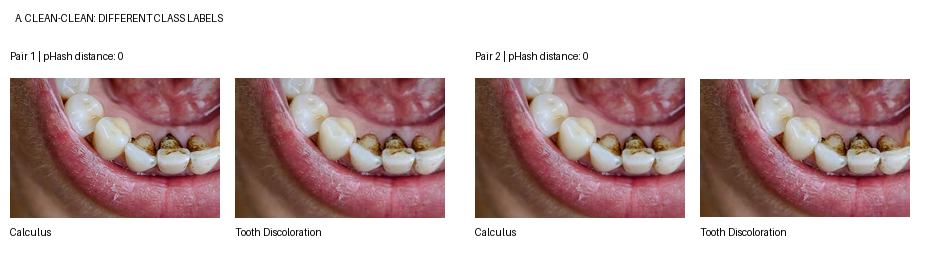


B. CLEAN-QUARANTINED SIMILARITY
Saved: /kaggle/working/oral_6class/near_duplicates_quarantined.png


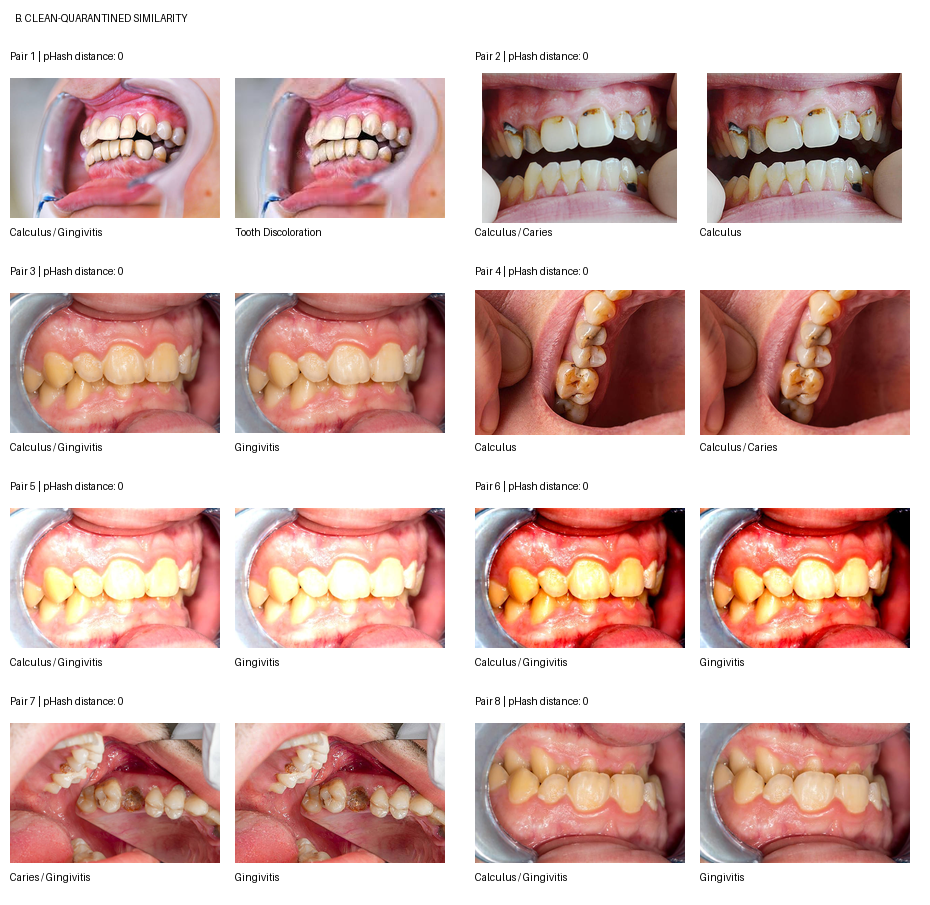


C. CLEAN-CLEAN: SAME CLASS
Saved: /kaggle/working/oral_6class/near_duplicates_same_class.png


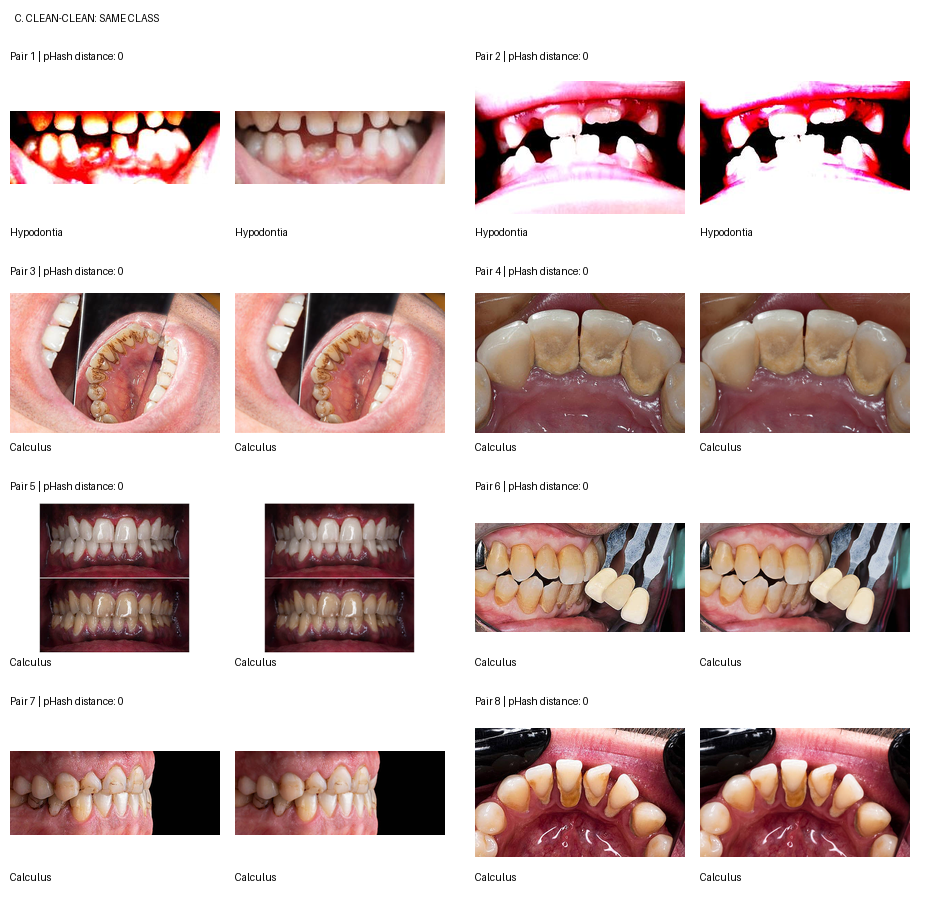


SECTION 2 - CELL 7 COMPLETED

No images have been deleted.
Visual review is required before filtering.


In [10]:
# ============================================================
# SECTION 2 - CELL 7
# VISUAL INSPECTION OF POTENTIAL NEAR-DUPLICATES
# ============================================================

import pandas as pd
from pathlib import Path
from PIL import Image, ImageOps, ImageDraw
from IPython.display import display

OUTPUT_DIR = Path("/kaggle/working/oral_6class")

pairs = pd.read_csv(
    OUTPUT_DIR / "potential_near_duplicate_pairs.csv"
)

print("=" * 65)
print("NEAR-DUPLICATE VISUAL VERIFICATION")
print("=" * 65)

# ------------------------------------------------------------
# 1. Categorize suspicious pairs
# ------------------------------------------------------------

pairs["different_labels"] = (
    pairs["labels_a"] != pairs["labels_b"]
)

cross_class = pairs[
    (pairs["pair_type"] == "Clean-Clean")
    & pairs["different_labels"]
]

quarantined = pairs[
    pairs["pair_type"] == "Clean-Quarantined"
]

same_class = pairs[
    (pairs["pair_type"] == "Clean-Clean")
    & (~pairs["different_labels"])
]

print("\nPOTENTIAL DUPLICATE CATEGORIES")
print("-" * 65)

print("Clean-Clean, different labels:", len(cross_class))
print("Clean-Quarantined pairs      :", len(quarantined))
print("Clean-Clean, same label      :", len(same_class))


# ------------------------------------------------------------
# 2. Select diverse examples
# ------------------------------------------------------------

def select_examples(data, n=8):

    data = data.sort_values(
        "phash_distance"
    )

    selected = []
    used_hashes = set()

    for _, row in data.iterrows():

        # Avoid repeatedly displaying the same image
        if (
            row["sha_a"] in used_hashes
            or row["sha_b"] in used_hashes
        ):
            continue

        selected.append(row)

        used_hashes.add(row["sha_a"])
        used_hashes.add(row["sha_b"])

        if len(selected) == n:
            break

    return selected


# ------------------------------------------------------------
# 3. Create side-by-side comparison sheets
# ------------------------------------------------------------

def make_contact_sheet(rows, title, filename):

    if not rows:
        print(f"\nNo pairs found for {title}")
        return

    thumb_w = 210
    thumb_h = 150

    tile_w = 465
    tile_h = 215

    columns = 2
    sheet_rows = (len(rows) + 1) // 2

    sheet = Image.new(
        "RGB",
        (columns * tile_w, sheet_rows * tile_h + 45),
        "white"
    )

    draw = ImageDraw.Draw(sheet)

    draw.text(
        (15, 12),
        title,
        fill="black"
    )

    for index, row in enumerate(rows):

        col = index % columns
        r = index // columns

        x = col * tile_w + 10
        y = r * tile_h + 50

        draw.text(
            (x, y),
            f"Pair {index + 1} | pHash distance: "
            f"{row['phash_distance']}",
            fill="black"
        )

        for side, key in enumerate(["a", "b"]):

            path = row[f"path_{key}"]

            with Image.open(path) as img:

                img = ImageOps.exif_transpose(img)
                img = img.convert("RGB")

                # Preserve the full image without cropping
                img.thumbnail(
                    (thumb_w, thumb_h),
                    Image.Resampling.LANCZOS
                )

                canvas = Image.new(
                    "RGB",
                    (thumb_w, thumb_h),
                    "white"
                )

                px = (thumb_w - img.width) // 2
                py = (thumb_h - img.height) // 2

                canvas.paste(img, (px, py))

            ix = x + side * 225
            iy = y + 23

            sheet.paste(canvas, (ix, iy))

            label = str(row[f"labels_{key}"])

            draw.text(
                (ix, iy + thumb_h + 3),
                label[:28],
                fill="black"
            )

    save_path = OUTPUT_DIR / filename

    sheet.save(save_path)

    print(f"\n{title}")
    print("Saved:", save_path)

    display(sheet)


# ------------------------------------------------------------
# 4. Show suspicious cross-class pairs
# ------------------------------------------------------------

make_contact_sheet(
    select_examples(cross_class),
    "A. CLEAN-CLEAN: DIFFERENT CLASS LABELS",
    "near_duplicates_cross_class.png"
)


# ------------------------------------------------------------
# 5. Show clean-quarantined pairs
# ------------------------------------------------------------

make_contact_sheet(
    select_examples(quarantined),
    "B. CLEAN-QUARANTINED SIMILARITY",
    "near_duplicates_quarantined.png"
)


# ------------------------------------------------------------
# 6. Show same-class near-duplicates
# ------------------------------------------------------------

make_contact_sheet(
    select_examples(same_class),
    "C. CLEAN-CLEAN: SAME CLASS",
    "near_duplicates_same_class.png"
)

print("\n" + "=" * 65)
print("SECTION 2 - CELL 7 COMPLETED")
print("=" * 65)

print("\nNo images have been deleted.")
print("Visual review is required before filtering.")

In [11]:
# ============================================================
# SECTION 2 - CELL 8
# NEAR-DUPLICATE GROUPING AND CONFLICT ANALYSIS
# ============================================================

import pandas as pd
from pathlib import Path

OUTPUT_DIR = Path("/kaggle/working/oral_6class")

# ------------------------------------------------------------
# 1. Load existing reports
# ------------------------------------------------------------

images = pd.read_csv(
    OUTPUT_DIR / "perceptual_hash_inventory.csv"
)

pairs = pd.read_csv(
    OUTPUT_DIR / "potential_near_duplicate_pairs.csv"
)

clean = pd.read_csv(
    OUTPUT_DIR / "exact_deduplicated_manifest.csv"
)

print("=" * 65)
print("NEAR-DUPLICATE GROUP ANALYSIS")
print("=" * 65)

print("Unique images:", len(images))
print("Potential similar pairs:", len(pairs))
print("Current clean candidates:", len(clean))


# ------------------------------------------------------------
# 2. Union-Find for grouping related images
# ------------------------------------------------------------

parent = {
    h: h
    for h in images["sha256"]
}

def find(x):

    if parent[x] != x:
        parent[x] = find(parent[x])

    return parent[x]


def union(a, b):

    root_a = find(a)
    root_b = find(b)

    if root_a != root_b:
        parent[root_b] = root_a


# Connect all potentially related images
for row in pairs.itertuples(index=False):

    union(row.sha_a, row.sha_b)


# ------------------------------------------------------------
# 3. Assign provisional group IDs
# ------------------------------------------------------------

images["group_root"] = images["sha256"].apply(find)

roots = sorted(images["group_root"].unique())

group_mapping = {
    root: f"NG_{i:05d}"
    for i, root in enumerate(roots, start=1)
}

images["near_duplicate_group"] = (
    images["group_root"].map(group_mapping)
)


# ------------------------------------------------------------
# 4. Summarize groups
# ------------------------------------------------------------

def collect_labels(values):

    labels = set()

    for value in values:

        labels.update(
            str(value).split(" / ")
        )

    return " / ".join(sorted(labels))


group_summary = (
    images.groupby("near_duplicate_group")
    .agg(
        unique_images=("sha256", "count"),
        labels=("labels", collect_labels),

        clean_images=(
            "status",
            lambda x: (x == "Clean").sum()
        ),

        quarantined_images=(
            "status",
            lambda x: (x == "Quarantined").sum()
        )
    )
    .reset_index()
)

group_summary["different_labels"] = (
    group_summary["labels"]
    .apply(lambda x: len(x.split(" / ")) > 1)
)

group_summary["contains_quarantined"] = (
    group_summary["quarantined_images"] > 0
)

group_summary["needs_review"] = (
    group_summary["different_labels"]
    | group_summary["contains_quarantined"]
)


# ------------------------------------------------------------
# 5. Attach group information to clean images
# ------------------------------------------------------------

clean = clean.merge(
    images[
        ["sha256", "near_duplicate_group"]
    ],
    on="sha256",
    how="left",
    validate="one_to_one"
)

clean = clean.merge(
    group_summary[
        [
            "near_duplicate_group",
            "unique_images",
            "different_labels",
            "contains_quarantined",
            "needs_review"
        ]
    ],
    on="near_duplicate_group",
    how="left",
    validate="many_to_one"
)


# ------------------------------------------------------------
# 6. Print summary
# ------------------------------------------------------------

print("\n" + "=" * 65)
print("GROUPING RESULTS")
print("=" * 65)

print(
    "Total provisional groups:",
    len(group_summary)
)

print(
    "Groups with multiple images:",
    int((group_summary["unique_images"] > 1).sum())
)

print(
    "Groups containing different labels:",
    int(group_summary["different_labels"].sum())
)

print(
    "Groups connected to quarantined images:",
    int(group_summary["contains_quarantined"].sum())
)

print(
    "Clean candidates needing review:",
    int(clean["needs_review"].sum())
)

print(
    "Clean candidates not flagged for label review:",
    int((~clean["needs_review"]).sum())
)


# ------------------------------------------------------------
# 7. Show largest groups
# ------------------------------------------------------------

print("\nLARGEST NEAR-DUPLICATE GROUPS")
print("-" * 65)

display(
    group_summary.sort_values(
        "unique_images",
        ascending=False
    ).head(15)
)


# ------------------------------------------------------------
# 8. Identify high-priority review groups
# ------------------------------------------------------------

review_groups = group_summary[
    group_summary["needs_review"]
].copy()

print("\nHIGH-PRIORITY REVIEW GROUPS")
print("-" * 65)

print("Groups requiring review:", len(review_groups))

display(
    review_groups.sort_values(
        "unique_images",
        ascending=False
    ).head(15)
)


# ------------------------------------------------------------
# 9. Save reports
# ------------------------------------------------------------

images.to_csv(
    OUTPUT_DIR / "near_duplicate_group_inventory.csv",
    index=False
)

group_summary.to_csv(
    OUTPUT_DIR / "near_duplicate_group_summary.csv",
    index=False
)

clean.to_csv(
    OUTPUT_DIR / "clean_candidates_with_groups.csv",
    index=False
)

review_groups.to_csv(
    OUTPUT_DIR / "near_duplicate_groups_for_review.csv",
    index=False
)


# ------------------------------------------------------------
# 10. Finish
# ------------------------------------------------------------

print("\n" + "=" * 65)
print("SECTION 2 - CELL 8 COMPLETED")
print("=" * 65)

print("\nNo additional images were removed.")

print(
    "Provisional groups created for "
    "leakage-aware dataset preparation."
)

print("\nReports saved to:", OUTPUT_DIR)

NEAR-DUPLICATE GROUP ANALYSIS
Unique images: 3899
Potential similar pairs: 1740
Current clean candidates: 3507

GROUPING RESULTS
Total provisional groups: 2890
Groups with multiple images: 397
Groups containing different labels: 387
Groups connected to quarantined images: 386
Clean candidates needing review: 35
Clean candidates not flagged for label review: 3472

LARGEST NEAR-DUPLICATE GROUPS
-----------------------------------------------------------------


,near_duplicate_group,unique_images,labels,clean_images,quarantined_images,different_labels,contains_quarantined,needs_review
1611,NG_01612,8,Hypodontia,8,0,False,False,False
429,NG_00430,7,Calculus / Tooth Discoloration,7,0,True,False,True
223,NG_00224,6,Calculus / Gingivitis,3,3,True,True,True
1758,NG_01759,6,Calculus,6,0,False,False,False
436,NG_00437,5,Hypodontia,5,0,False,False,False
297,NG_00298,5,Gingivitis,5,0,False,False,False
1103,NG_01104,5,Calculus,5,0,False,False,False
77,NG_00078,5,Hypodontia,5,0,False,False,False
302,NG_00303,5,Hypodontia,5,0,False,False,False
2708,NG_02709,5,Hypodontia,5,0,False,False,False



HIGH-PRIORITY REVIEW GROUPS
-----------------------------------------------------------------
Groups requiring review: 387


,near_duplicate_group,unique_images,labels,clean_images,quarantined_images,different_labels,contains_quarantined,needs_review
429,NG_00430,7,Calculus / Tooth Discoloration,7,0,True,False,True
223,NG_00224,6,Calculus / Gingivitis,3,3,True,True,True
405,NG_00406,5,Calculus / Caries,4,1,True,True,True
943,NG_00944,5,Calculus / Gingivitis,1,4,True,True,True
556,NG_00557,5,Caries / Gingivitis,4,1,True,True,True
1344,NG_01345,4,Caries / Gingivitis,3,1,True,True,True
426,NG_00427,3,Caries / Gingivitis,2,1,True,True,True
458,NG_00459,3,Calculus / Caries,2,1,True,True,True
2051,NG_02052,3,Calculus / Gingivitis / Tooth Discoloration,1,2,True,True,True
449,NG_00450,2,Calculus / Gingivitis,1,1,True,True,True



SECTION 2 - CELL 8 COMPLETED

No additional images were removed.
Provisional groups created for leakage-aware dataset preparation.

Reports saved to: /kaggle/working/oral_6class


HIGH-PRIORITY LABEL CONFLICT REVIEW

Groups requiring visual review: 17
Clean images involved: 35
Quarantined images connected: 22

GROUP SUMMARY
-----------------------------------------------------------------


,near_duplicate_group,unique_images,labels,clean_images,quarantined_images
0,NG_00430,7,Calculus / Tooth Discoloration,7,0
1,NG_00406,5,Calculus / Caries,4,1
2,NG_00557,5,Caries / Gingivitis,4,1
3,NG_00224,6,Calculus / Gingivitis,3,3
4,NG_01345,4,Caries / Gingivitis,3,1
5,NG_00427,3,Caries / Gingivitis,2,1
6,NG_00459,3,Calculus / Caries,2,1
7,NG_00944,5,Calculus / Gingivitis,1,4
8,NG_02052,3,Calculus / Gingivitis / Tooth Discoloration,1,2
9,NG_00104,2,Calculus / Gingivitis,1,1



CONTACT SHEET 1
Saved: /kaggle/working/oral_6class/priority_conflicts_page_01.png


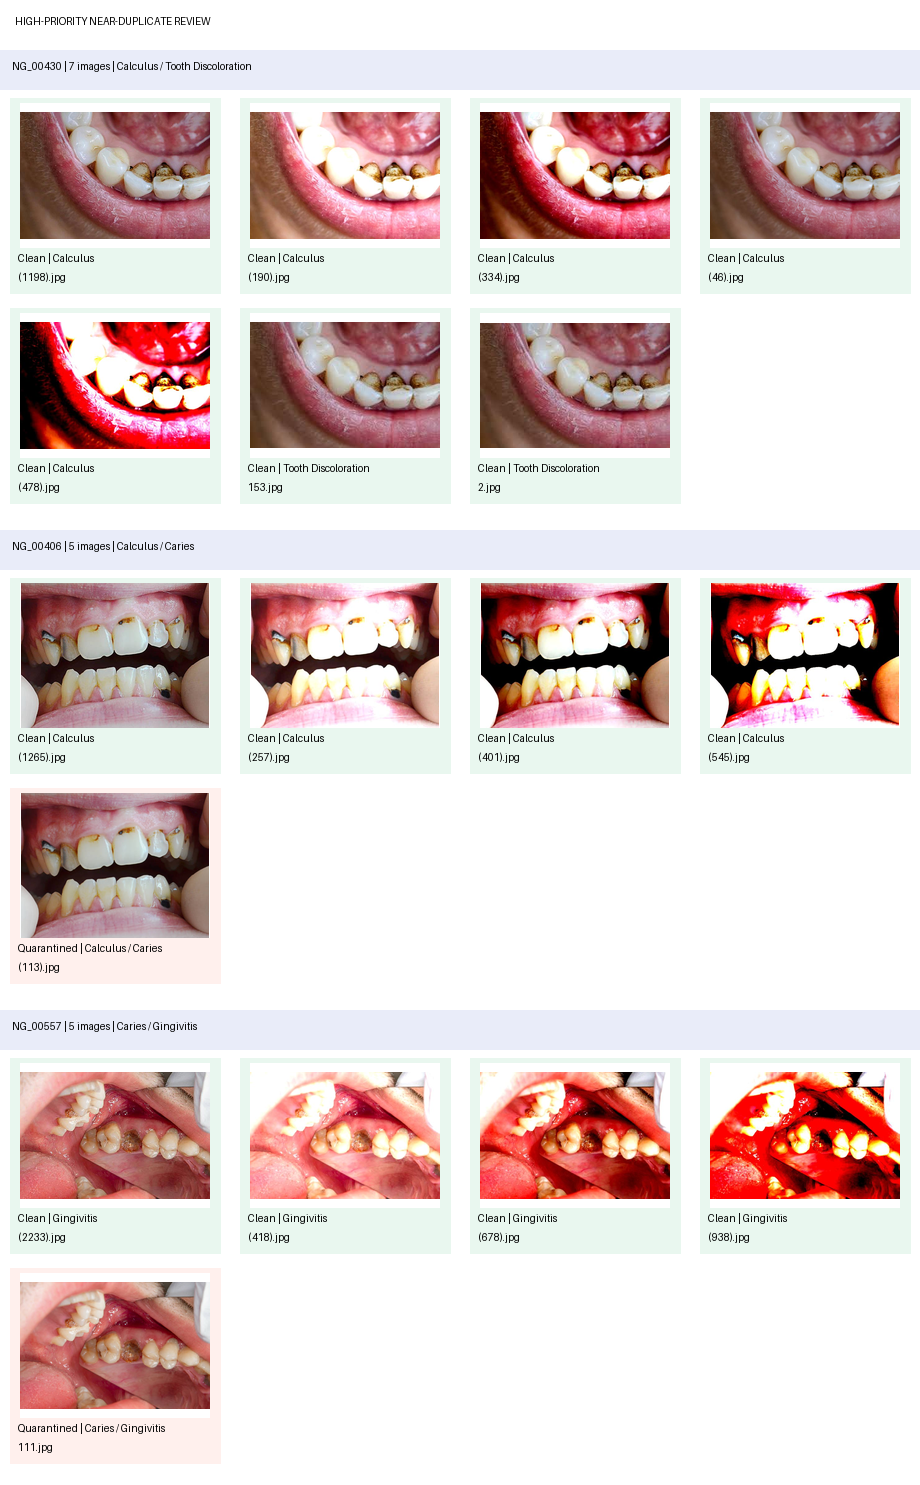


CONTACT SHEET 2
Saved: /kaggle/working/oral_6class/priority_conflicts_page_02.png


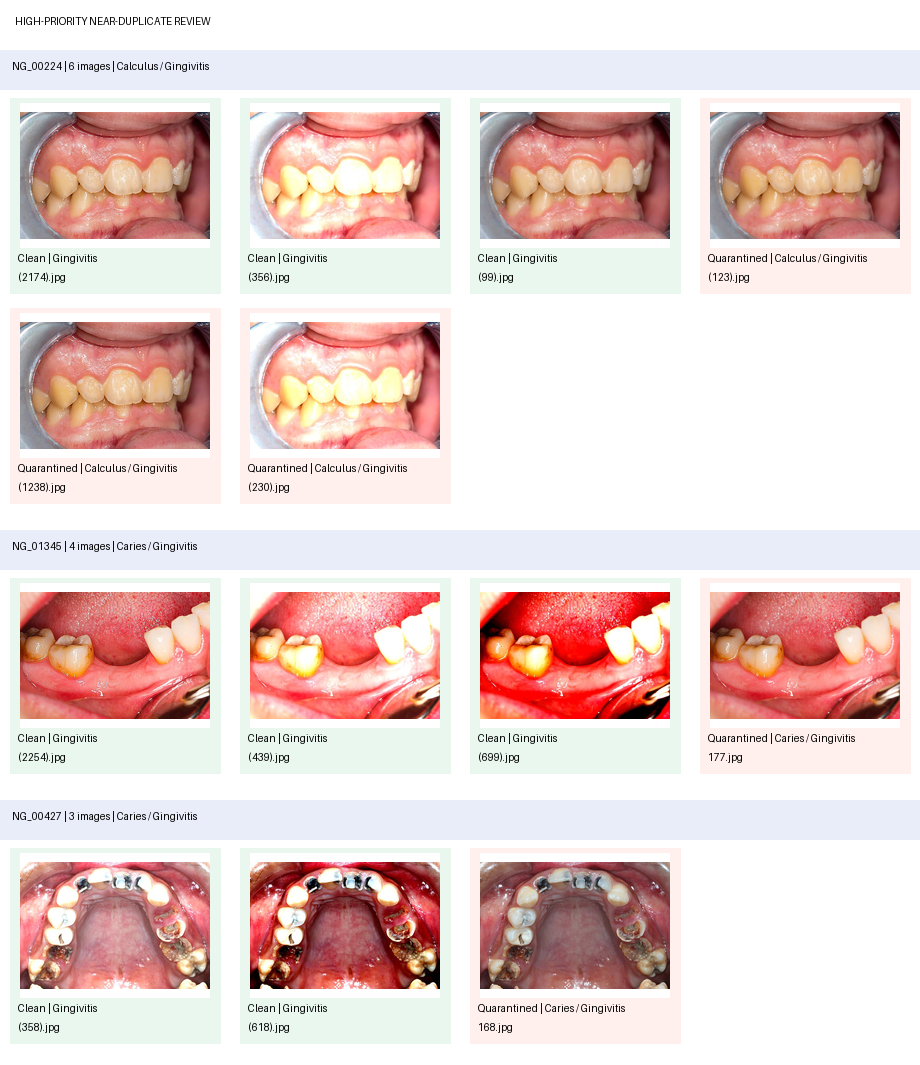


CONTACT SHEET 3
Saved: /kaggle/working/oral_6class/priority_conflicts_page_03.png


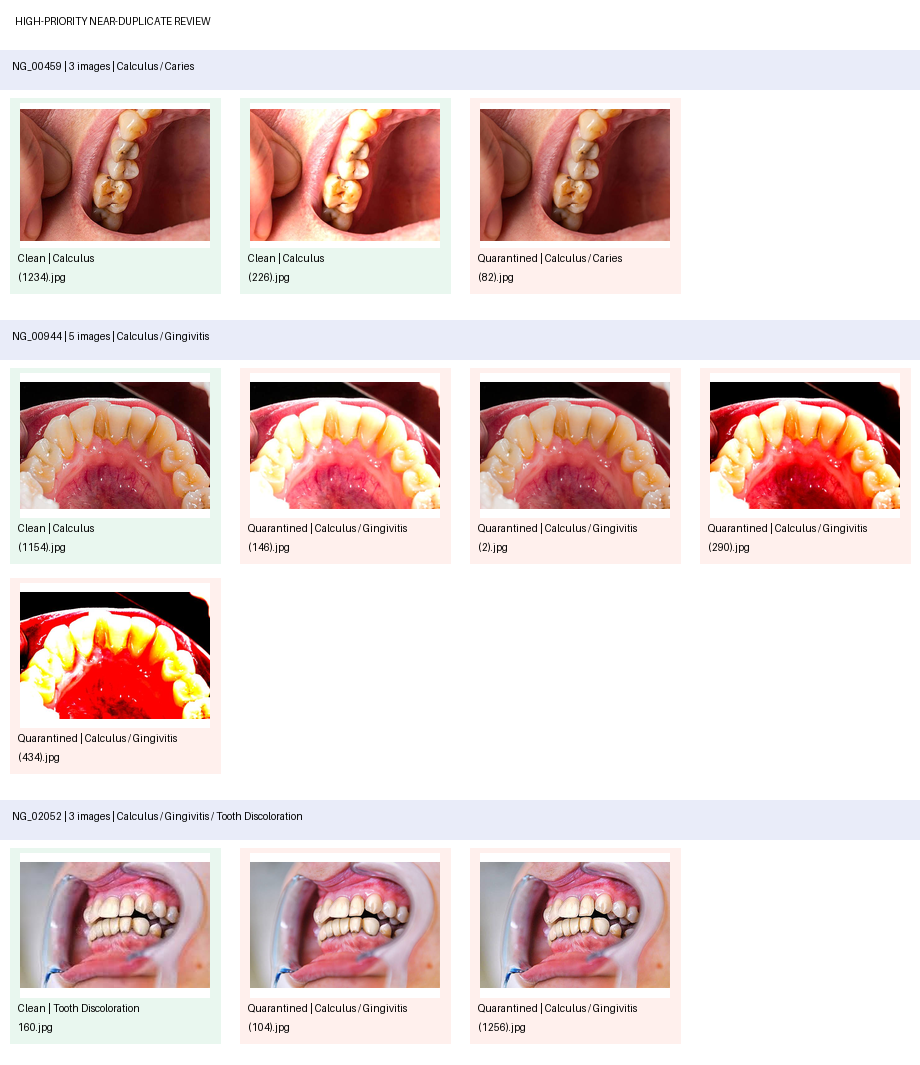


CONTACT SHEET 4
Saved: /kaggle/working/oral_6class/priority_conflicts_page_04.png


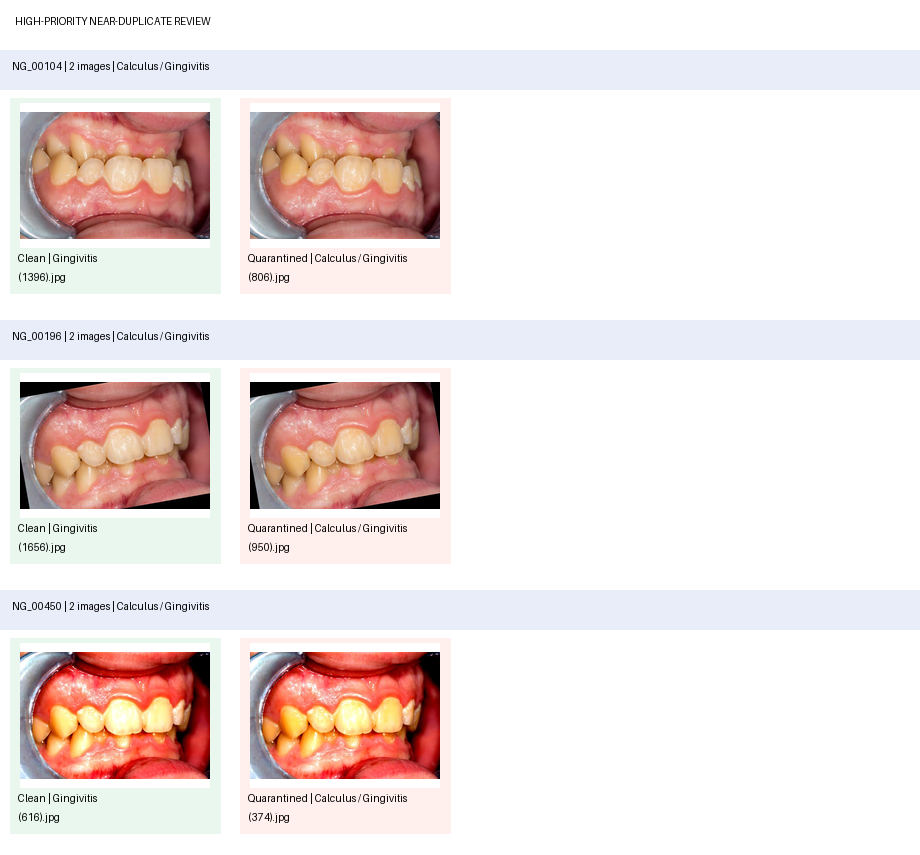


CONTACT SHEET 5
Saved: /kaggle/working/oral_6class/priority_conflicts_page_05.png


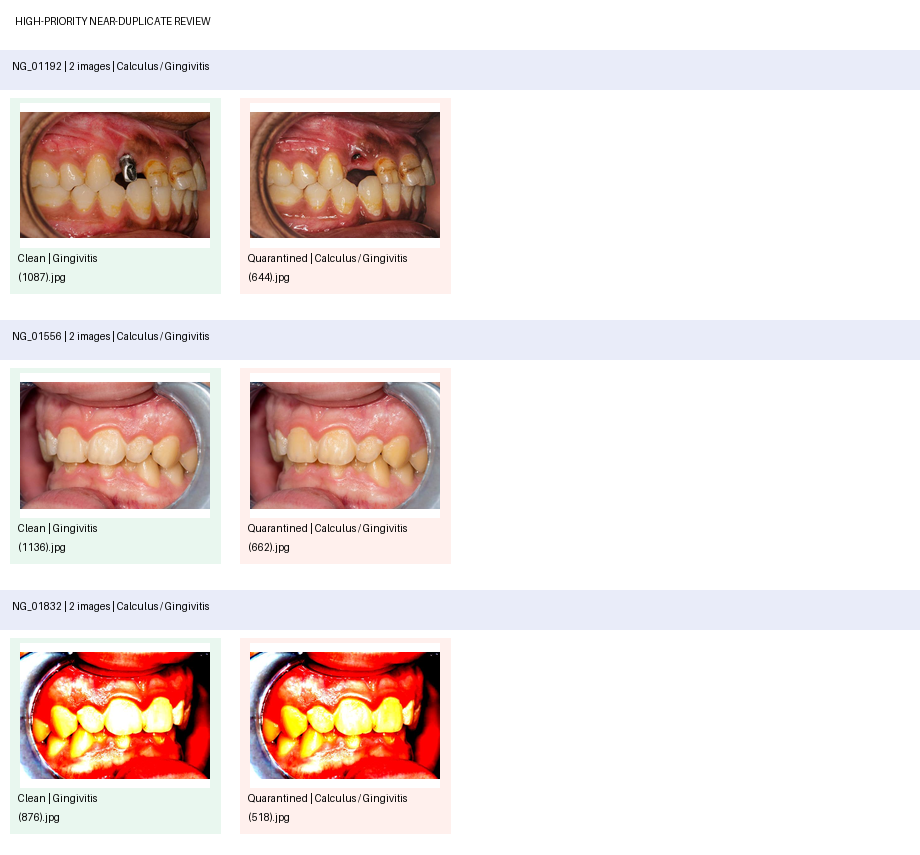


CONTACT SHEET 6
Saved: /kaggle/working/oral_6class/priority_conflicts_page_06.png


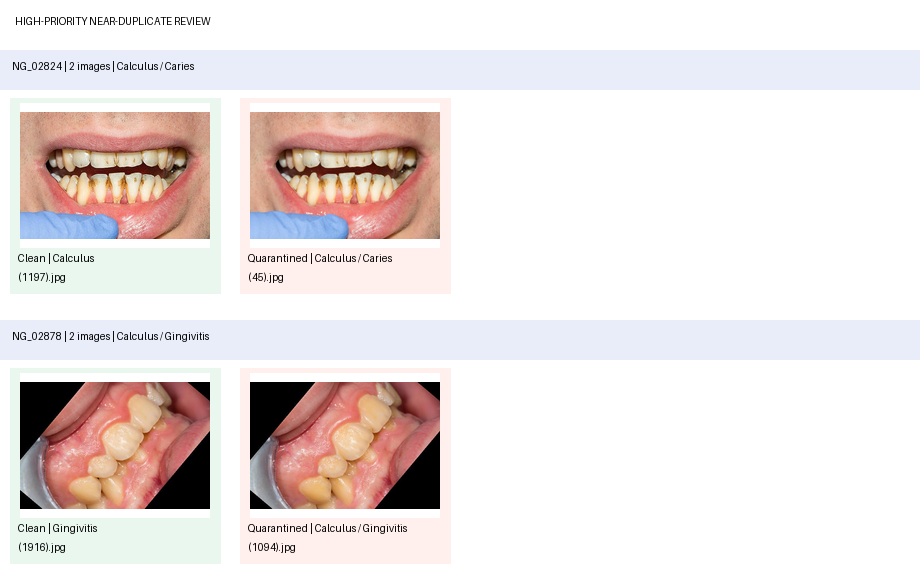


SECTION 2 - CELL 9 COMPLETED
Groups reviewed visually: 17
Contact sheets generated: 6

No images were removed.
Manual review is still required.


In [12]:
# ============================================================
# SECTION 2 - CELL 9
# VISUAL REVIEW OF HIGH-PRIORITY LABEL CONFLICTS
# ============================================================

import pandas as pd
from pathlib import Path
from PIL import Image, ImageOps, ImageDraw
from IPython.display import display
from math import ceil

OUTPUT_DIR = Path("/kaggle/working/oral_6class")

# ------------------------------------------------------------
# 1. Load near-duplicate group information
# ------------------------------------------------------------

images = pd.read_csv(
    OUTPUT_DIR / "near_duplicate_group_inventory.csv"
)

groups = pd.read_csv(
    OUTPUT_DIR / "near_duplicate_group_summary.csv"
)

print("=" * 65)
print("HIGH-PRIORITY LABEL CONFLICT REVIEW")
print("=" * 65)

# ------------------------------------------------------------
# 2. Select groups containing suspicious clean images
# ------------------------------------------------------------

review_groups = groups[
    (groups["clean_images"] > 0)
    & (groups["needs_review"])
].copy()

review_groups = review_groups.sort_values(
    ["clean_images", "unique_images"],
    ascending=[False, False]
).reset_index(drop=True)

group_ids = review_groups[
    "near_duplicate_group"
].tolist()

print("\nGroups requiring visual review:", len(group_ids))

print(
    "Clean images involved:",
    int(review_groups["clean_images"].sum())
)

print(
    "Quarantined images connected:",
    int(review_groups["quarantined_images"].sum())
)

print("\nGROUP SUMMARY")
print("-" * 65)

display(
    review_groups[
        [
            "near_duplicate_group",
            "unique_images",
            "labels",
            "clean_images",
            "quarantined_images"
        ]
    ]
)

# ------------------------------------------------------------
# 3. Contact sheet settings
# ------------------------------------------------------------

TILE_WIDTH = 230
TILE_HEIGHT = 210
COLUMNS = 4
GROUPS_PER_SHEET = 3

SHEET_WIDTH = TILE_WIDTH * COLUMNS

saved_sheets = []

# ------------------------------------------------------------
# 4. Generate contact sheets
# ------------------------------------------------------------

for page_start in range(
    0,
    len(group_ids),
    GROUPS_PER_SHEET
):

    page_groups = group_ids[
        page_start:page_start + GROUPS_PER_SHEET
    ]

    blocks = []
    total_height = 45

    # Prepare each group
    for group_id in page_groups:

        members = images[
            images["near_duplicate_group"] == group_id
        ].copy()

        members = members.sort_values(
            ["status", "labels", "image_path"]
        )

        rows_needed = ceil(
            len(members) / COLUMNS
        )

        block_height = 60 + rows_needed * TILE_HEIGHT

        blocks.append(
            (group_id, members, block_height)
        )

        total_height += block_height

    # Create page
    sheet = Image.new(
        "RGB",
        (SHEET_WIDTH, total_height),
        "white"
    )

    draw = ImageDraw.Draw(sheet)

    draw.text(
        (15, 15),
        "HIGH-PRIORITY NEAR-DUPLICATE REVIEW",
        fill="black"
    )

    current_y = 50

    # --------------------------------------------------------
    # 5. Draw groups and images
    # --------------------------------------------------------

    for group_id, members, block_height in blocks:

        draw.rectangle(
            [
                0,
                current_y,
                SHEET_WIDTH - 1,
                current_y + 39
            ],
            fill="#e9ecf9"
        )

        labels = " / ".join(
            sorted(
                set(
                    label
                    for value in members["labels"]
                    for label in str(value).split(" / ")
                )
            )
        )

        draw.text(
            (12, current_y + 10),
            f"{group_id} | {len(members)} images | {labels}",
            fill="black"
        )

        image_y = current_y + 48

        for index, row in enumerate(
            members.itertuples(index=False)
        ):

            col = index % COLUMNS
            row_num = index // COLUMNS

            x = col * TILE_WIDTH + 10
            y = image_y + row_num * TILE_HEIGHT

            # Background identifies clean vs quarantined
            background = (
                "#e9f7ef"
                if row.status == "Clean"
                else "#fff0ed"
            )

            draw.rectangle(
                [x, y, x + 210, y + 195],
                fill=background
            )

            try:

                with Image.open(row.image_path) as img:

                    img = ImageOps.exif_transpose(img)
                    img = img.convert("RGB")

                    img.thumbnail(
                        (190, 145),
                        Image.Resampling.LANCZOS
                    )

                    preview = Image.new(
                        "RGB",
                        (190, 145),
                        "white"
                    )

                    px = (190 - img.width) // 2
                    py = (145 - img.height) // 2

                    preview.paste(img, (px, py))

                sheet.paste(
                    preview,
                    (x + 10, y + 5)
                )

            except Exception as exc:

                draw.text(
                    (x + 10, y + 25),
                    f"Image error: {str(exc)[:18]}",
                    fill="red"
                )

            draw.text(
                (x + 8, y + 154),
                f"{row.status} | {str(row.labels)[:23]}",
                fill="black"
            )

            draw.text(
                (x + 8, y + 173),
                Path(row.image_path).name[:28],
                fill="black"
            )

        current_y += block_height

    # --------------------------------------------------------
    # 6. Save and display
    # --------------------------------------------------------

    page_number = (
        page_start // GROUPS_PER_SHEET
    ) + 1

    save_path = (
        OUTPUT_DIR
        / f"priority_conflicts_page_{page_number:02d}.png"
    )

    sheet.save(save_path)

    saved_sheets.append(str(save_path))

    print(f"\nCONTACT SHEET {page_number}")
    print("Saved:", save_path)

    display(sheet)

# ------------------------------------------------------------
# 7. Save review list
# ------------------------------------------------------------

review_groups.to_csv(
    OUTPUT_DIR / "priority_conflict_groups.csv",
    index=False
)

pd.DataFrame({
    "contact_sheet": saved_sheets
}).to_csv(
    OUTPUT_DIR / "priority_contact_sheet_index.csv",
    index=False
)

print("\n" + "=" * 65)
print("SECTION 2 - CELL 9 COMPLETED")
print("=" * 65)

print("Groups reviewed visually:", len(group_ids))
print("Contact sheets generated:", len(saved_sheets))

print("\nNo images were removed.")
print("Manual review is still required.")

In [13]:
# ============================================================
# SECTION 2 - CELL 10
# QUARANTINE CONFIRMED HIGH-RISK NEAR-DUPLICATE GROUPS
# ============================================================

import pandas as pd
from pathlib import Path

OUTPUT_DIR = Path("/kaggle/working/oral_6class")

print("=" * 65)
print("HIGH-RISK NEAR-DUPLICATE CLEANING")
print("=" * 65)

# ------------------------------------------------------------
# 1. Load existing clean candidates
# ------------------------------------------------------------

clean_df = pd.read_csv(
    OUTPUT_DIR / "clean_candidates_with_groups.csv"
)

review_df = pd.read_csv(
    OUTPUT_DIR / "priority_conflict_groups.csv"
)

print("\nImages before cleaning:", len(clean_df))

# ------------------------------------------------------------
# 2. Identify the 17 suspicious groups
# ------------------------------------------------------------

review_group_ids = set(
    review_df["near_duplicate_group"]
)

print("Groups selected for quarantine:", len(review_group_ids))

# ------------------------------------------------------------
# 3. Separate suspicious and retained images
# ------------------------------------------------------------

quarantine_mask = (
    clean_df["near_duplicate_group"]
    .isin(review_group_ids)
)

quarantined_df = clean_df[
    quarantine_mask
].copy()

final_candidates_df = clean_df[
    ~quarantine_mask
].copy()

final_candidates_df = (
    final_candidates_df
    .reset_index(drop=True)
)

# ------------------------------------------------------------
# 4. Verify expected exclusions
# ------------------------------------------------------------

print("\nNewly quarantined images:", len(quarantined_df))
print("Remaining candidates:", len(final_candidates_df))

assert len(clean_df) == 3507, (
    "Unexpected input count. Review previous steps."
)

assert len(quarantined_df) == 35, (
    "Expected 35 suspicious clean images."
)

assert len(final_candidates_df) == 3472, (
    "Unexpected remaining image count."
)

# ------------------------------------------------------------
# 5. Check remaining group label consistency
# ------------------------------------------------------------

group_label_counts = (
    final_candidates_df
    .groupby("near_duplicate_group")["class_name"]
    .nunique()
)

remaining_conflict_groups = int(
    (group_label_counts > 1).sum()
)

print(
    "\nRemaining groups with conflicting labels:",
    remaining_conflict_groups
)

assert remaining_conflict_groups == 0, (
    "Some groups still contain different class labels."
)

# ------------------------------------------------------------
# 6. Updated class distribution
# ------------------------------------------------------------

CLASS_NAMES = [
    "Calculus",
    "Caries",
    "Gingivitis",
    "Hypodontia",
    "Mouth Ulcer",
    "Tooth Discoloration"
]

before_counts = (
    clean_df["class_name"]
    .value_counts()
    .reindex(CLASS_NAMES, fill_value=0)
)

after_counts = (
    final_candidates_df["class_name"]
    .value_counts()
    .reindex(CLASS_NAMES, fill_value=0)
)

comparison_df = pd.DataFrame({
    "Class": CLASS_NAMES,
    "Before": before_counts.values,
    "After": after_counts.values
})

comparison_df["Newly_Quarantined"] = (
    comparison_df["Before"]
    - comparison_df["After"]
)

print("\nUPDATED CLASS DISTRIBUTION")
print("-" * 65)

display(comparison_df)

# ------------------------------------------------------------
# 7. Check remaining quality flags
# ------------------------------------------------------------

quality_flags = (
    final_candidates_df["quality_flag"]
    .fillna("None")
    .astype(str)
)

flagged_count = int(
    (quality_flags != "None").sum()
)

print("\nQUALITY STATUS")
print("-" * 65)

print("Remaining images:", len(final_candidates_df))
print("Quality-flagged images:", flagged_count)

# ------------------------------------------------------------
# 8. Examine remaining near-duplicate groups
# ------------------------------------------------------------

group_sizes = (
    final_candidates_df
    .groupby("near_duplicate_group")
    .size()
)

print("\nNEAR-DUPLICATE GROUP STATUS")
print("-" * 65)

print("Total retained groups:", len(group_sizes))

print(
    "Groups with multiple retained images:",
    int((group_sizes > 1).sum())
)

print(
    "Images in multi-image groups:",
    int(group_sizes[group_sizes > 1].sum())
)

# ------------------------------------------------------------
# 9. Save results
# ------------------------------------------------------------

final_candidates_df.to_csv(
    OUTPUT_DIR / "clean_after_conflict_review.csv",
    index=False
)

quarantined_df.to_csv(
    OUTPUT_DIR / "newly_quarantined_near_duplicates.csv",
    index=False
)

comparison_df.to_csv(
    OUTPUT_DIR / "updated_class_distribution.csv",
    index=False
)

# ------------------------------------------------------------
# 10. Final summary
# ------------------------------------------------------------

print("\n" + "=" * 65)
print("SECTION 2 - CELL 10 COMPLETED")
print("=" * 65)

print("Previous candidates :", len(clean_df))
print("Newly quarantined   :", len(quarantined_df))
print("Remaining candidates:", len(final_candidates_df))

print("\nAll original Kaggle files remain unchanged.")

print(
    "\nNOTE: Remaining same-class near-duplicates "
    "and quality flags still need review."
)

print("\n✅ HIGH-RISK CONFLICT CLEANING COMPLETED!")

HIGH-RISK NEAR-DUPLICATE CLEANING

Images before cleaning: 3507
Groups selected for quarantine: 17

Newly quarantined images: 35
Remaining candidates: 3472

Remaining groups with conflicting labels: 0

UPDATED CLASS DISTRIBUTION
-----------------------------------------------------------------


,Class,Before,After,Newly_Quarantined
0,Calculus,449,436,13
1,Caries,191,191,0
2,Gingivitis,1236,1217,19
3,Hypodontia,1215,1215,0
4,Mouth Ulcer,243,243,0
5,Tooth Discoloration,173,170,3



QUALITY STATUS
-----------------------------------------------------------------
Remaining images: 3472
Quality-flagged images: 441

NEAR-DUPLICATE GROUP STATUS
-----------------------------------------------------------------
Total retained groups: 2503
Groups with multiple retained images: 380
Images in multi-image groups: 1349

SECTION 2 - CELL 10 COMPLETED
Previous candidates : 3507
Newly quarantined   : 35
Remaining candidates: 3472

All original Kaggle files remain unchanged.

NOTE: Remaining same-class near-duplicates and quality flags still need review.

✅ HIGH-RISK CONFLICT CLEANING COMPLETED!


QUALITY-FLAGGED IMAGE REVIEW

Total remaining images: 3472
Quality-flagged images: 441
Unflagged images: 3031

QUALITY ISSUES BY CLASS
-----------------------------------------------------------------


quality_flag,Extreme Aspect Ratio,Low Resolution,"Low Resolution, Extreme Aspect Ratio"
class_name,,,
Calculus,54,0,0
Caries,1,6,0
Gingivitis,0,0,0
Hypodontia,18,171,189
Mouth Ulcer,1,0,0
Tooth Discoloration,1,0,0



Representative images selected: 8

QUALITY REVIEW SHEET 1


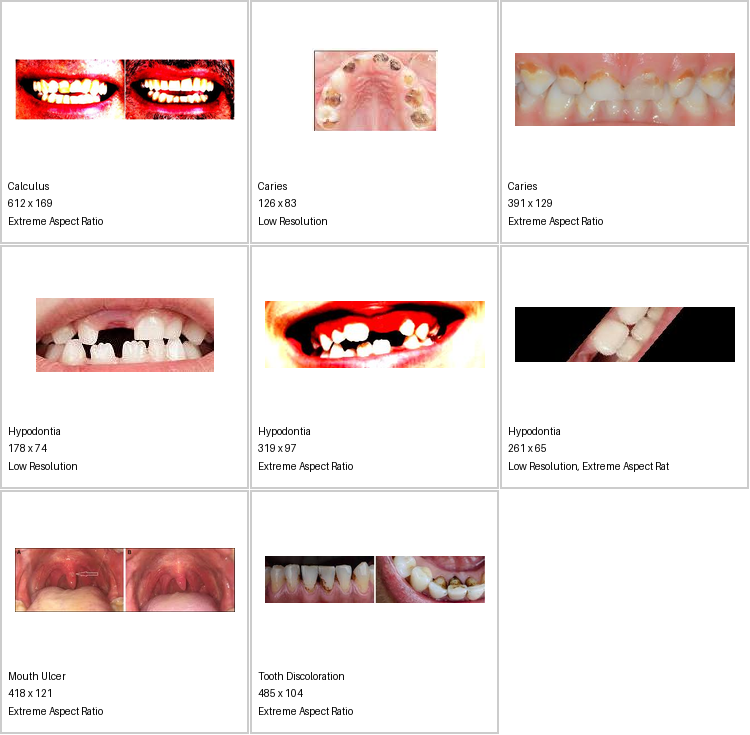


SECTION 2 - CELL 11 COMPLETED
Remaining images: 3472
Flagged images: 441
Contact sheets generated: 1

No images have been removed.


In [14]:
# ============================================================
# SECTION 2 - CELL 11
# QUALITY-FLAGGED IMAGE VISUAL REVIEW
# ============================================================

import pandas as pd
from pathlib import Path
from PIL import Image, ImageOps, ImageDraw
from IPython.display import display

OUTPUT_DIR = Path("/kaggle/working/oral_6class")

# ------------------------------------------------------------
# 1. Load current cleaned candidates
# ------------------------------------------------------------

df = pd.read_csv(
    OUTPUT_DIR / "clean_after_conflict_review.csv"
)

CLASS_NAMES = [
    "Calculus",
    "Caries",
    "Gingivitis",
    "Hypodontia",
    "Mouth Ulcer",
    "Tooth Discoloration"
]

df["quality_flag"] = (
    df["quality_flag"]
    .fillna("None")
)

flagged = df[
    df["quality_flag"] != "None"
].copy()

print("=" * 65)
print("QUALITY-FLAGGED IMAGE REVIEW")
print("=" * 65)

print("\nTotal remaining images:", len(df))
print("Quality-flagged images:", len(flagged))
print("Unflagged images:", len(df) - len(flagged))

# ------------------------------------------------------------
# 2. Class-wise quality issues
# ------------------------------------------------------------

print("\nQUALITY ISSUES BY CLASS")
print("-" * 65)

quality_table = pd.crosstab(
    flagged["class_name"],
    flagged["quality_flag"]
)

display(
    quality_table.reindex(
        CLASS_NAMES,
        fill_value=0
    )
)

# ------------------------------------------------------------
# 3. Select representative images
# ------------------------------------------------------------

ISSUE_TYPES = [
    "Low Resolution",
    "Extreme Aspect Ratio",
    "Low Resolution, Extreme Aspect Ratio"
]

samples = []

for class_name in CLASS_NAMES:

    for issue in ISSUE_TYPES:

        subset = flagged[
            (flagged["class_name"] == class_name)
            & (flagged["quality_flag"] == issue)
        ]

        if not subset.empty:

            selected = subset.sample(
                n=1,
                random_state=42
            )

            samples.append(selected.iloc[0])

sample_df = pd.DataFrame(samples)

print("\nRepresentative images selected:", len(sample_df))

# ------------------------------------------------------------
# 4. Generate contact sheets
# ------------------------------------------------------------

TILE_W = 250
TILE_H = 245

COLUMNS = 3
IMAGES_PER_SHEET = 9

saved_files = []

for start in range(
    0,
    len(sample_df),
    IMAGES_PER_SHEET
):

    subset = sample_df.iloc[
        start:start + IMAGES_PER_SHEET
    ]

    rows = (len(subset) + COLUMNS - 1) // COLUMNS

    sheet = Image.new(
        "RGB",
        (COLUMNS * TILE_W, rows * TILE_H),
        "white"
    )

    draw = ImageDraw.Draw(sheet)

    for index, (_, record) in enumerate(
        subset.iterrows()
    ):

        col = index % COLUMNS
        row = index // COLUMNS

        x = col * TILE_W
        y = row * TILE_H

        draw.rectangle(
            [x, y, x + TILE_W - 2, y + TILE_H - 2],
            outline="#cccccc",
            width=2
        )

        try:

            with Image.open(record["image_path"]) as img:

                img = ImageOps.exif_transpose(img)
                img = img.convert("RGB")

                img.thumbnail(
                    (220, 170),
                    Image.Resampling.LANCZOS
                )

                px = x + (TILE_W - img.width) // 2
                py = y + 5 + (170 - img.height) // 2

                sheet.paste(img, (px, py))

        except Exception as exc:

            draw.text(
                (x + 10, y + 30),
                f"Error: {str(exc)[:25]}",
                fill="red"
            )

        draw.text(
            (x + 8, y + 180),
            str(record["class_name"])[:29],
            fill="black"
        )

        draw.text(
            (x + 8, y + 197),
            f"{int(record['width'])} x "
            f"{int(record['height'])}",
            fill="black"
        )

        draw.text(
            (x + 8, y + 215),
            str(record["quality_flag"])[:34],
            fill="black"
        )

    page_number = start // IMAGES_PER_SHEET + 1

    save_path = (
        OUTPUT_DIR /
        f"quality_review_page_{page_number:02d}.png"
    )

    sheet.save(save_path)

    saved_files.append(str(save_path))

    print(f"\nQUALITY REVIEW SHEET {page_number}")

    display(sheet)

# ------------------------------------------------------------
# 5. Save reports
# ------------------------------------------------------------

flagged.to_csv(
    OUTPUT_DIR / "remaining_quality_flagged.csv",
    index=False
)

sample_df.to_csv(
    OUTPUT_DIR / "quality_review_samples.csv",
    index=False
)

print("\n" + "=" * 65)
print("SECTION 2 - CELL 11 COMPLETED")
print("=" * 65)

print("Remaining images:", len(df))
print("Flagged images:", len(flagged))
print("Contact sheets generated:", len(saved_files))

print("\nNo images have been removed.")

In [15]:
# ============================================================
# SECTION 3 - CELL 12
# QUALITY DATASETS + LEAKAGE-AWARE SPLITTING
# ============================================================

import pandas as pd
from pathlib import Path
from sklearn.model_selection import train_test_split

OUTPUT_DIR = Path("/kaggle/working/oral_6class")
SEED = 42

CLASS_NAMES = [
    "Calculus",
    "Caries",
    "Gingivitis",
    "Hypodontia",
    "Mouth Ulcer",
    "Tooth Discoloration"
]

print("=" * 65)
print("DATASET PREPARATION AND GROUP-AWARE SPLITTING")
print("=" * 65)

# ------------------------------------------------------------
# 1. Load cleaned candidates
# ------------------------------------------------------------

df = pd.read_csv(
    OUTPUT_DIR / "clean_after_conflict_review.csv"
)

df["quality_flag"] = (
    df["quality_flag"]
    .fillna("None")
    .astype(str)
)

assert len(df) == 3472
assert df["sha256"].is_unique
assert df["near_duplicate_group"].notna().all()

# ------------------------------------------------------------
# 2. Verify groups have consistent class labels
# ------------------------------------------------------------

label_counts = (
    df.groupby("near_duplicate_group")["class_name"]
    .nunique()
)

assert label_counts.max() == 1, (
    "Conflicting labels remain within a group!"
)

# ------------------------------------------------------------
# 3. Create one row per near-duplicate group
# ------------------------------------------------------------

groups = (
    df.groupby("near_duplicate_group")
    .agg(
        class_name=("class_name", "first"),
        image_count=("image_path", "size")
    )
    .reset_index()
)

print("\nImages:", len(df))
print("Near-duplicate groups:", len(groups))

# ------------------------------------------------------------
# 4. Split groups - not individual images
# ------------------------------------------------------------

train_val_groups, test_groups = train_test_split(
    groups,
    test_size=0.15,
    random_state=SEED,
    stratify=groups["class_name"]
)

train_groups, val_groups = train_test_split(
    train_val_groups,
    test_size=0.15 / 0.85,
    random_state=SEED,
    stratify=train_val_groups["class_name"]
)

# ------------------------------------------------------------
# 5. Assign split to every image
# ------------------------------------------------------------

split_map = {}

for split_name, subset in [
    ("train", train_groups),
    ("val", val_groups),
    ("test", test_groups)
]:

    for group_id in subset["near_duplicate_group"]:

        split_map[group_id] = split_name

df["split"] = (
    df["near_duplicate_group"].map(split_map)
)

assert df["split"].notna().all()

# ------------------------------------------------------------
# 6. Verify no group leakage
# ------------------------------------------------------------

train_ids = set(train_groups["near_duplicate_group"])
val_ids = set(val_groups["near_duplicate_group"])
test_ids = set(test_groups["near_duplicate_group"])

assert train_ids.isdisjoint(val_ids)
assert train_ids.isdisjoint(test_ids)
assert val_ids.isdisjoint(test_ids)

print("\n✅ No near-duplicate group overlaps!")

# ------------------------------------------------------------
# 7. Create inclusive and strict-quality datasets
# ------------------------------------------------------------

inclusive_df = df.copy()

strict_df = df[
    df["quality_flag"] == "None"
].copy()

flagged_df = df[
    df["quality_flag"] != "None"
].copy()

print("\nDATASET VERSIONS")
print("-" * 65)

print("Inclusive images      :", len(inclusive_df))
print("Strict-quality images :", len(strict_df))
print("Flagged images        :", len(flagged_df))

assert len(inclusive_df) == 3472
assert len(strict_df) == 3031
assert len(flagged_df) == 441

# ------------------------------------------------------------
# 8. Class distribution comparison
# ------------------------------------------------------------

comparison = pd.DataFrame({
    "Class": CLASS_NAMES,

    "Inclusive": [
        (inclusive_df["class_name"] == c).sum()
        for c in CLASS_NAMES
    ],

    "Strict_Quality": [
        (strict_df["class_name"] == c).sum()
        for c in CLASS_NAMES
    ],

    "Quality_Flagged": [
        (flagged_df["class_name"] == c).sum()
        for c in CLASS_NAMES
    ]
})

print("\nCLASS DISTRIBUTION")
print("-" * 65)

display(comparison)

# ------------------------------------------------------------
# 9. Display class-wise split counts
# ------------------------------------------------------------

def show_split_distribution(data, title):

    print(f"\n{title}")
    print("-" * 65)

    table = pd.crosstab(
        data["class_name"],
        data["split"]
    )

    table = table.reindex(
        index=CLASS_NAMES,
        columns=["train", "val", "test"],
        fill_value=0
    )

    table["Total"] = table.sum(axis=1)

    display(table)

    return table

inclusive_table = show_split_distribution(
    inclusive_df,
    "INCLUSIVE DATASET SPLITS"
)

strict_table = show_split_distribution(
    strict_df,
    "STRICT-QUALITY DATASET SPLITS"
)

# ------------------------------------------------------------
# 10. Save complete datasets
# ------------------------------------------------------------

inclusive_df.to_csv(
    OUTPUT_DIR / "inclusive_split_manifest.csv",
    index=False
)

strict_df.to_csv(
    OUTPUT_DIR / "strict_split_manifest.csv",
    index=False
)

flagged_df.to_csv(
    OUTPUT_DIR / "flagged_images_with_splits.csv",
    index=False
)

# ------------------------------------------------------------
# 11. Save individual train / val / test files
# ------------------------------------------------------------

for dataset_name, dataset in [
    ("inclusive", inclusive_df),
    ("strict", strict_df)
]:

    for split_name in ["train", "val", "test"]:

        subset = dataset[
            dataset["split"] == split_name
        ].copy()

        subset.to_csv(
            OUTPUT_DIR /
            f"{dataset_name}_{split_name}.csv",
            index=False
        )

# ------------------------------------------------------------
# 12. Save group assignments
# ------------------------------------------------------------

group_assignments = groups.copy()

group_assignments["split"] = (
    group_assignments["near_duplicate_group"]
    .map(split_map)
)

group_assignments.to_csv(
    OUTPUT_DIR / "group_split_assignments.csv",
    index=False
)

# ------------------------------------------------------------
# 13. Final verification
# ------------------------------------------------------------

for dataset in [inclusive_df, strict_df]:

    assert dataset["sha256"].is_unique

    assert (
        dataset.groupby("near_duplicate_group")["split"]
        .nunique()
        .max()
    ) == 1

print("\n" + "=" * 65)
print("SECTION 3 - CELL 12 COMPLETED")
print("=" * 65)

print("\n✅ Inclusive dataset prepared")
print("✅ Strict-quality dataset prepared")
print("✅ Group-aware splits generated")
print("✅ No exact duplicate leakage")
print("✅ No provisional group overlap")
print("✅ All CSV manifests saved")

print("\nOutput directory:", OUTPUT_DIR)

print(
    "\nIMPORTANT: Preserve these split files."
    "\nDo not tune models using the test split."
    "\nPatient-level independence is not verified."
)

DATASET PREPARATION AND GROUP-AWARE SPLITTING

Images: 3472
Near-duplicate groups: 2503

✅ No near-duplicate group overlaps!

DATASET VERSIONS
-----------------------------------------------------------------
Inclusive images      : 3472
Strict-quality images : 3031
Flagged images        : 441

CLASS DISTRIBUTION
-----------------------------------------------------------------


,Class,Inclusive,Strict_Quality,Quality_Flagged
0,Calculus,436,382,54
1,Caries,191,184,7
2,Gingivitis,1217,1217,0
3,Hypodontia,1215,837,378
4,Mouth Ulcer,243,242,1
5,Tooth Discoloration,170,169,1



INCLUSIVE DATASET SPLITS
-----------------------------------------------------------------


split,train,val,test,Total
class_name,,,,
Calculus,307,71,58,436
Caries,135,28,28,191
Gingivitis,850,167,200,1217
Hypodontia,840,180,195,1215
Mouth Ulcer,167,37,39,243
Tooth Discoloration,119,26,25,170



STRICT-QUALITY DATASET SPLITS
-----------------------------------------------------------------


split,train,val,test,Total
class_name,,,,
Calculus,264,63,55,382
Caries,130,27,27,184
Gingivitis,850,167,200,1217
Hypodontia,567,130,140,837
Mouth Ulcer,166,37,39,242
Tooth Discoloration,119,26,24,169



SECTION 3 - CELL 12 COMPLETED

✅ Inclusive dataset prepared
✅ Strict-quality dataset prepared
✅ Group-aware splits generated
✅ No exact duplicate leakage
✅ No provisional group overlap
✅ All CSV manifests saved

Output directory: /kaggle/working/oral_6class

IMPORTANT: Preserve these split files.
Do not tune models using the test split.
Patient-level independence is not verified.


In [16]:
# ============================================================
# SAVE CLEANED DATASET REPORTS AND FIXED SPLITS
# ============================================================

from pathlib import Path
from zipfile import ZipFile, ZIP_DEFLATED
from IPython.display import FileLink

OUTPUT_DIR = Path("/kaggle/working/oral_6class")

BACKUP_PATH = Path(
    "/kaggle/working/ORAL_6CLASS_CLEANED_DATA.zip"
)

csv_files = sorted(OUTPUT_DIR.glob("*.csv"))

assert csv_files, "No cleaning reports found!"

with ZipFile(BACKUP_PATH, "w", ZIP_DEFLATED) as zipf:

    for file in csv_files:
        zipf.write(file, arcname=file.name)

print("✅ CLEANED DATASET BACKUP CREATED!")

print("Total CSV files:", len(csv_files))

print("\nIMPORTANT SPLIT FILES:")

for name in [
    "strict_train.csv",
    "strict_val.csv",
    "strict_test.csv",
    "inclusive_train.csv",
    "inclusive_val.csv",
    "inclusive_test.csv"
]:
    print(name, "✅" if (OUTPUT_DIR / name).exists() else "❌")

print("\nDOWNLOAD YOUR BACKUP:")
display(FileLink(str(BACKUP_PATH)))

✅ CLEANED DATASET BACKUP CREATED!
Total CSV files: 37

IMPORTANT SPLIT FILES:
strict_train.csv ✅
strict_val.csv ✅
strict_test.csv ✅
inclusive_train.csv ✅
inclusive_val.csv ✅
inclusive_test.csv ✅

DOWNLOAD YOUR BACKUP:


/kaggle/working/ORAL_6CLASS_CLEANED_DATA.zip

In [17]:
# ============================================================
# EXPORT CLEANED DATASET FOR NEW TRAINING NOTEBOOK
# ============================================================

from pathlib import Path
from zipfile import ZipFile, ZIP_DEFLATED
from IPython.display import FileLink
import pandas as pd

OUTPUT_DIR = Path("/kaggle/working/oral_6class")

ZIP_PATH = Path(
    "/kaggle/working/ORALSENSE_CLEANED_DATASET.zip"
)

splits = {}

for split in ["train", "val", "test"]:

    df = pd.read_csv(
        OUTPUT_DIR / f"strict_{split}.csv"
    )

    splits[split] = df.copy()

print("Packaging cleaned images...")

with ZipFile(
    ZIP_PATH,
    "w",
    compression=ZIP_DEFLATED,
    compresslevel=1
) as archive:

    saved_images = set()

    for split, df in splits.items():

        relative_paths = []

        for row in df.itertuples(index=False):

            original_path = Path(row.image_path)

            assert original_path.is_file(), (
                f"Missing image: {original_path}"
            )

            # Use unique image hashes as filenames
            image_name = (
                str(row.sha256)
                + original_path.suffix.lower()
            )

            relative_path = f"images/{image_name}"

            if relative_path not in saved_images:

                archive.write(
                    original_path,
                    arcname=relative_path
                )

                saved_images.add(relative_path)

            relative_paths.append(relative_path)

        # Save portable relative image paths
        df["image_path"] = relative_paths

        archive.writestr(
            f"manifests/{split}.csv",
            df.to_csv(index=False)
        )

print("\n✅ CLEANED DATASET EXPORTED!")

print("Images packed:", len(saved_images))

for split, df in splits.items():
    print(f"{split}: {len(df)} images")

print("\nZIP size:",
      round(ZIP_PATH.stat().st_size / (1024**2), 2),
      "MB")

print("\nDOWNLOAD:")
display(FileLink(str(ZIP_PATH)))

Packaging cleaned images...

✅ CLEANED DATASET EXPORTED!
Images packed: 3031
train: 2096 images
val: 450 images
test: 485 images

ZIP size: 65.87 MB

DOWNLOAD:


/kaggle/working/ORALSENSE_CLEANED_DATASET.zip